# RFM Segmentation and Customer Insight Analysis
### Python Project — Retail Analytics

**Objective:** Clean and validate transaction data, calculate Recency, Frequency and Monetary (RFM) metrics, score customers using quantiles, create interpretable customer segments, visualize customer and revenue distributions, and develop evidence-based business recommendations.

This notebook addresses the 10 objective tasks and supports the 8 subjective questions in the project brief.

**Dataset expected:** `rfm_data.csv` with the columns `CustomerID`, `PurchaseDate`, `TransactionAmount`, `ProductInformation`, `OrderID`, and `Location`.

> **Important analytical limitation:** The supplied data contains transaction dates from April to June 2023, product labels, location, transaction amount and identifiers. It does not contain customer feedback, returns, costs, discounts, or detailed product attributes. Some subjective questions therefore can be answered only as recommendations or with explicit limitations, rather than as measured findings.

## 1. Import libraries and configure the analysis

The notebook uses common Python data-analysis libraries. If a library is not installed in your environment, install it with `pip install pandas numpy matplotlib seaborn`.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 2. Load the dataset

Place `rfm_data.csv` in the same folder as this notebook, or update `DATA_PATH` to its location. The loader checks a few common locations and stops with a clear error if the file cannot be found.

In [28]:

from pathlib import Path
import pandas as pd

# Specify the dataset path
DATA_PATH = Path("C:/Users/Hari/Downloads/RFM Project/rfm_data.csv")

# Check whether the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at: {DATA_PATH}"
    )

# Load the dataset
raw = pd.read_csv(DATA_PATH)

# Create a working copy
data = raw.copy()

# Display dataset information
print(f"Rows: {data.shape[0]:,}")
print(f"Columns: {data.shape[1]:,}")

display(data.head())


Rows: 1,000
Columns: 6


,CustomerID,PurchaseDate,TransactionAmount,ProductInformation,OrderID,Location
0,8814,2023-04-11,943.31,Product C,890075,Tokyo
1,2188,2023-04-11,463.70,Product A,176819,London
2,4608,2023-04-11,80.28,Product A,340062,New York
3,2559,2023-04-11,221.29,Product A,239145,London
4,9482,2023-04-11,739.56,Product A,194545,Paris


## 3. Inspect structure and data quality

We inspect column names, data types, missing values, exact duplicate rows, unique counts, and basic numeric summaries before transforming the data.

In [4]:
print("Column names:")
print(data.columns.tolist())

print("\nData types:")
display(data.dtypes.rename("dtype").to_frame())

quality_summary = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2),
    "unique_values": data.nunique(dropna=True),
    "dtype": data.dtypes.astype(str),
})
display(quality_summary)

print(f"Exact duplicate rows: {data.duplicated().sum():,}")
display(data.describe(include="all").T)

Column names:
['CustomerID', 'PurchaseDate', 'TransactionAmount', 'ProductInformation', 'OrderID', 'Location']

Data types:


,dtype
CustomerID,int64
PurchaseDate,object
TransactionAmount,float64
ProductInformation,object
OrderID,int64
Location,object


,missing_count,missing_percent,unique_values,dtype
CustomerID,0,0.00,946,int64
PurchaseDate,0,0.00,61,object
TransactionAmount,0,0.00,997,float64
ProductInformation,0,0.00,4,object
OrderID,0,0.00,1000,int64
Location,0,0.00,4,object


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,"1,000.00",NaN,NaN,NaN,"5,554.79","2,605.01","1,011.00","3,273.00","5,538.00","7,821.75","9,991.00"
PurchaseDate,1000,61,2023-05-04,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TransactionAmount,"1,000.00",NaN,NaN,NaN,513.68,286.10,12.13,257.12,523.57,759.86,999.44
ProductInformation,1000,4,Product C,277,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrderID,"1,000.00",NaN,NaN,NaN,"554,071.40","264,695.45","100,096.00","313,152.00","564,671.50","783,052.25","999,695.00"
Location,1000,4,Tokyo,278,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Clean and validate the data

Cleaning choices are made explicitly:
- Standardize column names by trimming surrounding whitespace.
- Convert identifiers to strings so they are treated as labels, not measurements.
- Parse purchase dates with invalid dates coerced to missing, then report and exclude invalid rows from transaction-based analysis.
- Convert transaction amounts to numeric values and exclude missing or non-finite amounts.
- Remove exact duplicate rows only. We do **not** automatically remove repeated customers, because repeat purchases are essential to RFM analysis.
- Check for duplicate `OrderID` values. If any exist, they require investigation before assuming one row equals one order.

In [5]:
data.columns = data.columns.str.strip()

required_columns = [
    "CustomerID", "PurchaseDate", "TransactionAmount",
    "ProductInformation", "OrderID", "Location"
]
missing_columns = sorted(set(required_columns) - set(data.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {missing_columns}")

rows_before = len(data)
data = data.drop_duplicates().copy()
exact_duplicates_removed = rows_before - len(data)

data["CustomerID"] = data["CustomerID"].astype("string").str.strip()
data["OrderID"] = data["OrderID"].astype("string").str.strip()
data["PurchaseDate"] = pd.to_datetime(data["PurchaseDate"], errors="coerce")
data["TransactionAmount"] = pd.to_numeric(data["TransactionAmount"], errors="coerce")

for col in ["ProductInformation", "Location"]:
    data[col] = data[col].astype("string").str.strip()

# Treat blank strings as missing in text columns.
for col in ["CustomerID", "OrderID", "ProductInformation", "Location"]:
    data[col] = data[col].replace("", pd.NA)

invalid_date_rows = data["PurchaseDate"].isna().sum()
invalid_amount_rows = data["TransactionAmount"].isna().sum()
nonpositive_amount_rows = (data["TransactionAmount"] <= 0).sum()

# Keep rows that have valid customer/order IDs, a valid date, and a valid positive amount.
valid_mask = (
    data["CustomerID"].notna()
    & data["OrderID"].notna()
    & data["PurchaseDate"].notna()
    & data["TransactionAmount"].notna()
    & np.isfinite(data["TransactionAmount"])
    & (data["TransactionAmount"] > 0)
)
invalid_rows_excluded = int((~valid_mask).sum())
data = data.loc[valid_mask].copy()

print(f"Exact duplicate rows removed: {exact_duplicates_removed:,}")
print(f"Rows with invalid/missing dates before exclusion: {invalid_date_rows:,}")
print(f"Rows with invalid/missing transaction amounts before exclusion: {invalid_amount_rows:,}")
print(f"Rows with non-positive amounts before exclusion: {nonpositive_amount_rows:,}")
print(f"Rows excluded by validation rules: {invalid_rows_excluded:,}")
print(f"Rows retained for analysis: {len(data):,}")

display(data.head())
display(data.isna().sum().rename("missing_after_cleaning").to_frame())

Exact duplicate rows removed: 0
Rows with invalid/missing dates before exclusion: 0
Rows with invalid/missing transaction amounts before exclusion: 0
Rows with non-positive amounts before exclusion: 0
Rows excluded by validation rules: 0
Rows retained for analysis: 1,000


,CustomerID,PurchaseDate,TransactionAmount,ProductInformation,OrderID,Location
0,8814,2023-04-11,943.31,Product C,890075,Tokyo
1,2188,2023-04-11,463.70,Product A,176819,London
2,4608,2023-04-11,80.28,Product A,340062,New York
3,2559,2023-04-11,221.29,Product A,239145,London
4,9482,2023-04-11,739.56,Product A,194545,Paris


,missing_after_cleaning
CustomerID,0
PurchaseDate,0
TransactionAmount,0
ProductInformation,0
OrderID,0
Location,0


### 4.1 Validate identifiers and transaction grain

A unique `OrderID` per row would support treating each row as an order. If order IDs repeat, we inspect them and aggregate order-level revenue carefully. The dataset description calls `OrderID` a unique order identifier, but the code verifies this assumption rather than relying on it blindly.

In [6]:
duplicate_order_rows = data["OrderID"].duplicated(keep=False).sum()
print(f"Rows belonging to a repeated OrderID: {duplicate_order_rows:,}")
print(f"Unique customers: {data['CustomerID'].nunique():,}")
print(f"Unique orders: {data['OrderID'].nunique():,}")
print(f"Date range: {data['PurchaseDate'].min().date()} to {data['PurchaseDate'].max().date()}")
print(f"Product labels: {data['ProductInformation'].nunique():,}")
print(f"Locations: {data['Location'].nunique():,}")

if duplicate_order_rows:
    display(
        data.loc[data["OrderID"].duplicated(keep=False)]
            .sort_values("OrderID")
            .head(20)
    )
    print(
        "Note: repeated OrderIDs exist. Frequency will count distinct orders; "
        "monetary value will sum transaction amounts at the transaction-row level. "
        "Confirm whether repeated IDs represent order lines before interpreting order-level totals."
    )
else:
    print("Each retained row has a unique OrderID; one row per order is supported by the data.")

Rows belonging to a repeated OrderID: 0
Unique customers: 946
Unique orders: 1,000
Date range: 2023-04-11 to 2023-06-10
Product labels: 4
Locations: 4
Each retained row has a unique OrderID; one row per order is supported by the data.


## 5. Exploratory data analysis (EDA)

These summaries describe the available transactions before customer-level segmentation.

In [7]:
overview = pd.Series({
    "Transactions / rows": len(data),
    "Unique customers": data["CustomerID"].nunique(),
    "Unique orders": data["OrderID"].nunique(),
    "Total revenue": data["TransactionAmount"].sum(),
    "Average transaction value": data["TransactionAmount"].mean(),
    "Median transaction value": data["TransactionAmount"].median(),
    "Date range (days, inclusive)": (data["PurchaseDate"].max().normalize() - data["PurchaseDate"].min().normalize()).days + 1,
})
display(overview.to_frame("value"))

print("Transaction amount summary:")
display(data["TransactionAmount"].describe().to_frame())

print("Transactions by product:")
display(
    data.groupby("ProductInformation", dropna=False)
        .agg(Orders=("OrderID", "nunique"),
             Revenue=("TransactionAmount", "sum"),
             Average_Transaction=("TransactionAmount", "mean"))
        .sort_values("Revenue", ascending=False)
)

,value
Transactions / rows,"1,000.00"
Unique customers,946.00
Unique orders,"1,000.00"
Total revenue,"513,677.81"
Average transaction value,513.68
Median transaction value,523.57
"Date range (days, inclusive)",61.00


Transaction amount summary:


,TransactionAmount
count,"1,000.00"
mean,513.68
std,286.10
min,12.13
25%,257.12
50%,523.57
75%,759.86
max,999.44


Transactions by product:


,Orders,Revenue,Average_Transaction
ProductInformation,,,
Product C,277,"144,491.49",521.63
Product D,253,"128,728.31",508.81
Product B,245,"123,038.08",502.20
Product A,225,"117,419.93",521.87


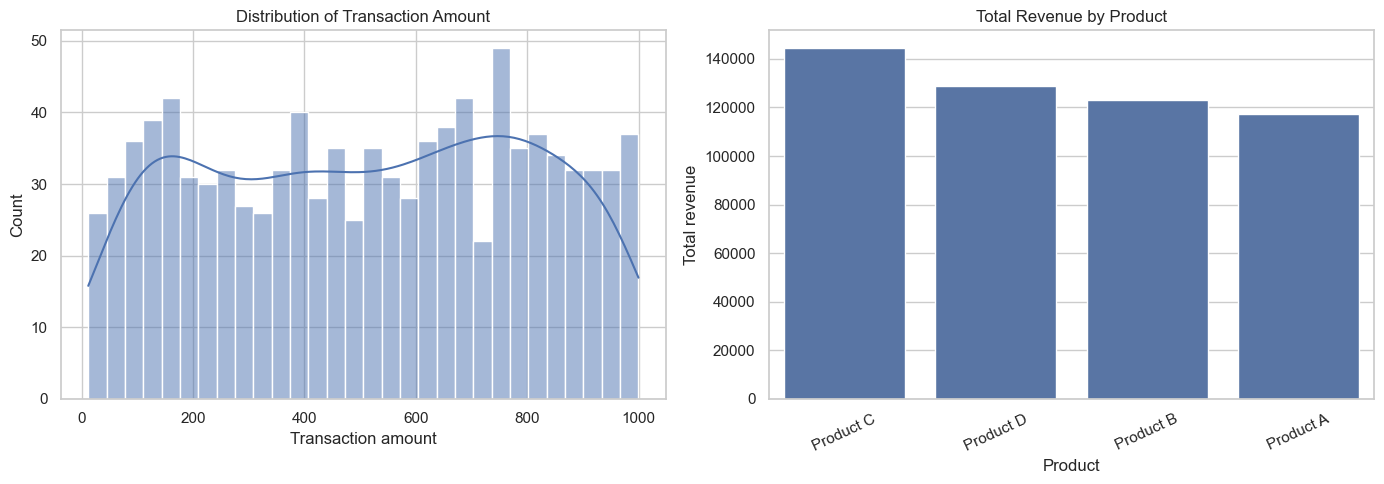

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=data, x="TransactionAmount", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Transaction Amount")
axes[0].set_xlabel("Transaction amount")

product_revenue = (
    data.groupby("ProductInformation")["TransactionAmount"]
        .sum().sort_values(ascending=False)
)
sns.barplot(x=product_revenue.index, y=product_revenue.values, ax=axes[1])
axes[1].set_title("Total Revenue by Product")
axes[1].set_xlabel("Product")
axes[1].set_ylabel("Total revenue")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## 6. Calculate customer-level RFM metrics

RFM definitions:
- **Recency:** number of days between the reference date and the customer's latest purchase. Lower is better.
- **Frequency:** number of distinct orders made by the customer. Higher is better.
- **Monetary:** sum of transaction amounts for the customer. Higher is better.

The default reference date is one day after the latest purchase in the dataset. This measures recency relative to the end of the observed data. If the business brief requires a fixed evaluation date, replace `REFERENCE_DATE` and document why.

In [9]:
REFERENCE_DATE = data["PurchaseDate"].max().normalize() + pd.Timedelta(days=1)
print("RFM reference date:", REFERENCE_DATE.date())

rfm = (
    data.groupby("CustomerID", as_index=False)
        .agg(
            LastPurchaseDate=("PurchaseDate", "max"),
            Frequency=("OrderID", "nunique"),
            MonetaryValue=("TransactionAmount", "sum"),
        )
)

rfm["Recency"] = (REFERENCE_DATE - rfm["LastPurchaseDate"].dt.normalize()).dt.days
rfm = rfm[["CustomerID", "LastPurchaseDate", "Recency", "Frequency", "MonetaryValue"]]

assert (rfm["Recency"] >= 0).all(), "Recency should not be negative."
assert (rfm["Frequency"] >= 1).all(), "Frequency should be at least one."
assert (rfm["MonetaryValue"] > 0).all(), "Monetary value should be positive."

print(f"Customer-level RFM rows: {len(rfm):,}")
display(rfm.head(10))
display(rfm[["Recency", "Frequency", "MonetaryValue"]].describe().T)

RFM reference date: 2023-06-11
Customer-level RFM rows: 946


,CustomerID,LastPurchaseDate,Recency,Frequency,MonetaryValue
0,1011,2023-05-08,34,2,"1,129.02"
1,1025,2023-05-20,22,1,359.29
2,1029,2023-06-10,1,1,704.99
3,1046,2023-04-28,44,1,859.82
4,1049,2023-05-28,14,1,225.72
5,1082,2023-05-17,25,1,600.69
6,1086,2023-06-01,10,1,100.18
7,1104,2023-05-07,35,1,146.12
8,1108,2023-05-13,29,1,883.21
9,1120,2023-05-13,29,1,999.44


,count,mean,std,min,25%,50%,75%,max
Recency,946.00,30.98,17.32,1.00,15.00,32.00,45.00,61.00
Frequency,946.00,1.06,0.25,1.00,1.00,1.00,1.00,3.00
MonetaryValue,946.00,543.00,324.38,12.13,266.64,542.89,782.69,"2,379.45"


## 7. Assign quantile-based RFM scores

We use five score levels. Recency is reversed because a smaller number of days since the last purchase is better. Frequency and Monetary are scored in ascending order.

Ties are common in frequency and may also occur in monetary values. To produce five score groups where possible, we rank values before applying `qcut`. `method="first"` breaks ties using the existing row order, so customers with identical metric values can receive different scores when a quantile boundary splits tied values. We report this limitation and preserve the raw metrics for interpretation.

In [10]:
def quantile_score(series, higher_is_better=True, q=5):
    """Return integer quantile scores 1..q; qcut uses ranks to handle tied values."""
    ranked = series.rank(method="first", ascending=True)
    labels = list(range(1, q + 1))
    if not higher_is_better:
        labels = labels[::-1]
    scores = pd.qcut(ranked, q=q, labels=labels)
    return scores.astype(int)

rfm["R_Score"] = quantile_score(rfm["Recency"], higher_is_better=False)
rfm["F_Score"] = quantile_score(rfm["Frequency"], higher_is_better=True)
rfm["M_Score"] = quantile_score(rfm["MonetaryValue"], higher_is_better=True)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int).astype(str)
    + rfm["F_Score"].astype(int).astype(str)
    + rfm["M_Score"].astype(int).astype(str)
)
rfm["RFM_Total_Score"] = rfm[["R_Score", "F_Score", "M_Score"]].sum(axis=1)

display(rfm.head(10))
print("Score distributions:")
for col in ["R_Score", "F_Score", "M_Score"]:
    display(rfm[col].value_counts().sort_index().rename("customers").to_frame().T)

,CustomerID,LastPurchaseDate,Recency,Frequency,MonetaryValue,R_Score,F_Score,M_Score,RFM_Score,RFM_Total_Score
0,1011,2023-05-08,34,2,"1,129.02",3,5,5,355,13
1,1025,2023-05-20,22,1,359.29,4,1,2,412,7
2,1029,2023-06-10,1,1,704.99,5,1,4,514,10
3,1046,2023-04-28,44,1,859.82,2,1,5,215,8
4,1049,2023-05-28,14,1,225.72,4,1,2,412,7
5,1082,2023-05-17,25,1,600.69,4,1,3,413,8
6,1086,2023-06-01,10,1,100.18,5,1,1,511,7
7,1104,2023-05-07,35,1,146.12,3,1,1,311,5
8,1108,2023-05-13,29,1,883.21,3,1,5,315,9
9,1120,2023-05-13,29,1,999.44,3,1,5,315,9


Score distributions:


R_Score,1,2,3,4,5
customers,189,189,189,189,190


F_Score,1,2,3,4,5
customers,190,189,189,189,189


M_Score,1,2,3,4,5
customers,190,189,189,189,189


## 8. Create interpretable RFM customer segments

The brief asks for customer segments. We use explicit score rules rather than arbitrary equal-width bins of a summed score. These rules are a practical, transparent segmentation scheme for this project; they are not universal industry standards.

Segment rules are evaluated from highest priority to lowest:
- **Champions:** high recency, frequency and monetary scores.
- **Loyal Customers:** high frequency, with at least moderate recency.
- **Potential Loyalists:** recent purchases and moderate-to-high frequency.
- **Recent Customers:** very recent customers whose frequency is still low.
- **Big Spenders:** high monetary score but not already assigned to a higher-priority segment.
- **At Risk:** low recency score with relatively high past frequency or monetary value.
- **Hibernating:** low recency, frequency and monetary scores.
- **Needs Attention:** all other customers.

These labels are descriptive of the observed transaction history, not a prediction of future churn. Because the observation window is short, churn risk should be interpreted cautiously.

In [11]:
def assign_segment(row):
    r, f, m = int(row["R_Score"]), int(row["F_Score"]), int(row["M_Score"])

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if f >= 4 and r >= 3:
        return "Loyal Customers"
    if r >= 4 and f >= 2:
        return "Potential Loyalists"
    if r == 5 and f == 1:
        return "Recent Customers"
    if m >= 4:
        return "Big Spenders"
    if r <= 2 and (f >= 3 or m >= 3):
        return "At Risk"
    if r <= 2 and f <= 2 and m <= 2:
        return "Hibernating"
    return "Needs Attention"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

segment_order = [
    "Champions", "Loyal Customers", "Potential Loyalists", "Recent Customers",
    "Big Spenders", "At Risk", "Hibernating", "Needs Attention"
]
rfm["Segment"] = pd.Categorical(rfm["Segment"], categories=segment_order, ordered=True)

segment_summary = (
    rfm.groupby("Segment", observed=False)
       .agg(
           Customers=("CustomerID", "nunique"),
           Revenue=("MonetaryValue", "sum"),
           Average_Recency_Days=("Recency", "mean"),
           Average_Frequency=("Frequency", "mean"),
           Average_Monetary_Value=("MonetaryValue", "mean"),
           Median_Monetary_Value=("MonetaryValue", "median"),
       )
       .reset_index()
)
segment_summary["Customer_Share_%"] = 100 * segment_summary["Customers"] / rfm["CustomerID"].nunique()
segment_summary["Revenue_Share_%"] = 100 * segment_summary["Revenue"] / rfm["MonetaryValue"].sum()

display(segment_summary.sort_values("Revenue", ascending=False).round(2))

,Segment,Customers,Revenue,Average_Recency_Days,Average_Frequency,Average_Monetary_Value,Median_Monetary_Value,Customer_Share_%,Revenue_Share_%
4,Big Spenders,202,"168,616.47",42.19,1.05,834.74,812.78,21.35,32.83
1,Loyal Customers,167,"79,475.72",21.63,1.12,475.90,450.90,17.65,15.47
2,Potential Loyalists,158,"76,240.90",12.71,1.00,482.54,475.70,16.70,14.84
5,At Risk,174,"64,484.01",49.14,1.01,370.60,394.76,18.39,12.55
0,Champions,62,"60,727.81",13.02,1.35,979.48,903.31,6.55,11.82
7,Needs Attention,84,"29,424.13",29.63,1.00,350.29,358.30,8.88,5.73
3,Recent Customers,39,"21,643.66",7.67,1.00,554.97,642.24,4.12,4.21
6,Hibernating,60,"13,065.11",50.37,1.00,217.75,200.80,6.34,2.54


## 9. Objective Task 5 — Customer distribution across RFM segments

We report both customer counts and customer-share percentages. Empty segments, if any, remain visible in the summary.

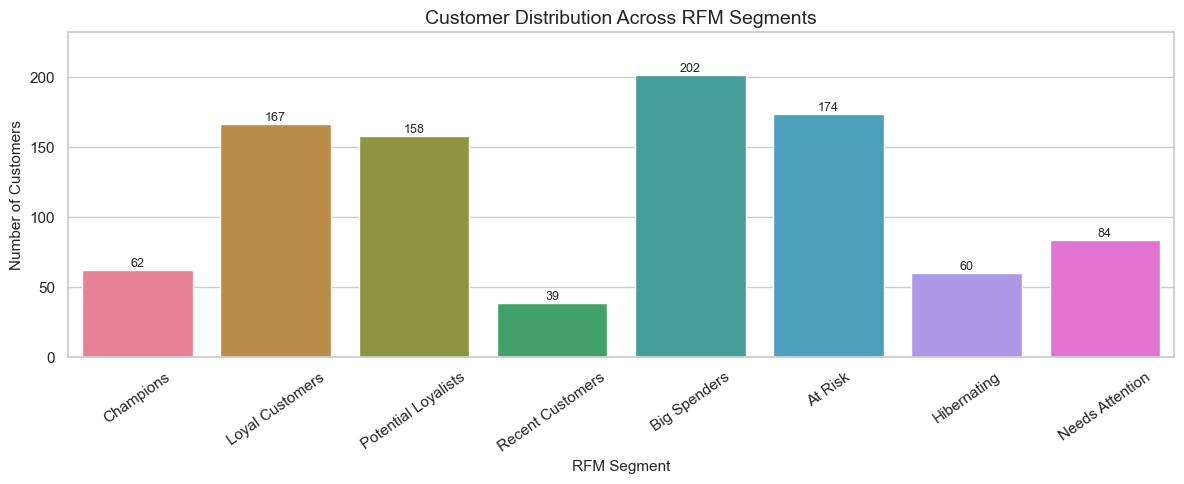

,Customers,Customer_Share_%
Segment,,
Champions,62,6.55
Loyal Customers,167,17.65
Potential Loyalists,158,16.70
Recent Customers,39,4.12
Big Spenders,202,21.35
At Risk,174,18.39
Hibernating,60,6.34
Needs Attention,84,8.88


In [30]:

customer_distribution = (
    rfm["Segment"].value_counts(sort=False)
       .reindex(segment_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    x=customer_distribution.index.astype(str),
    y=customer_distribution.values,
    hue=customer_distribution.index.astype(str),
    palette="husl",
    legend=False,
    ax=ax
)

ax.set_title("Customer Distribution Across RFM Segments", fontsize=14)
ax.set_xlabel("RFM Segment", fontsize=11)
ax.set_ylabel("Number of Customers", fontsize=11)
ax.tick_params(axis="x", rotation=35)

for i, value in enumerate(customer_distribution.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom", fontsize=9)

ax.set_ylim(0, max(customer_distribution.values) * 1.15)

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Customers": customer_distribution,
    "Customer_Share_%": (
        customer_distribution / len(rfm) * 100
    ).round(2)
}))


## 10. Objective Task 6 — Revenue contribution by segment

Revenue contribution is calculated as the sum of customer Monetary values in each segment. Revenue share is the segment's share of total observed revenue.

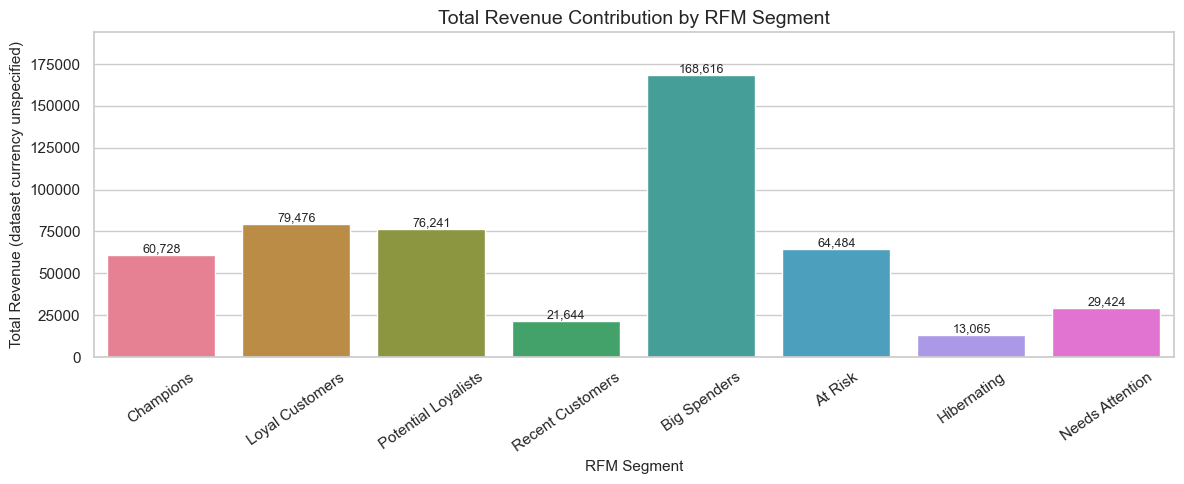

,Revenue,Revenue_Share_%
Segment,,
Big Spenders,"168,616.47",32.83
Loyal Customers,"79,475.72",15.47
Potential Loyalists,"76,240.90",14.84
At Risk,"64,484.01",12.55
Champions,"60,727.81",11.82
Needs Attention,"29,424.13",5.73
Recent Customers,"21,643.66",4.21
Hibernating,"13,065.11",2.54


In [34]:
# Calculate total revenue for each RFM segment
revenue_distribution = (
    rfm.groupby("Segment", observed=False)["MonetaryValue"]
       .sum()
       .reindex(segment_order, fill_value=0)
)

# Calculate each segment's percentage contribution to total revenue
total_revenue = revenue_distribution.sum()

if total_revenue > 0:
    revenue_share = revenue_distribution / total_revenue * 100
else:
    revenue_share = revenue_distribution * 0

# Create the bar chart
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    x=revenue_distribution.index.astype(str),
    y=revenue_distribution.values,
    hue=revenue_distribution.index.astype(str),
    palette="husl",
    legend=False,
    ax=ax
)

# Add chart titles and labels
ax.set_title("Total Revenue Contribution by RFM Segment", fontsize=14)
ax.set_xlabel("RFM Segment", fontsize=11)
ax.set_ylabel("Total Revenue (dataset currency unspecified)", fontsize=11)
ax.tick_params(axis="x", rotation=35)

# Display revenue values above each bar
for i, value in enumerate(revenue_distribution.values):
    ax.text(
        i,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add space above the bars so labels remain visible
max_revenue = revenue_distribution.max()

if max_revenue > 0:
    ax.set_ylim(0, max_revenue * 1.15)

plt.tight_layout()
plt.show()

# Display revenue and percentage contribution in a table
revenue_summary = pd.DataFrame({
    "Revenue": revenue_distribution,
    "Revenue_Share_%": revenue_share.round(2)
}).sort_values("Revenue", ascending=False)

display(revenue_summary)

## 11. Objective Tasks 7–9 — Distributions of Recency, Frequency and Monetary value

These plots use the **actual RFM metrics**, not their 1–5 scores. This preserves the meaning of the distributions.

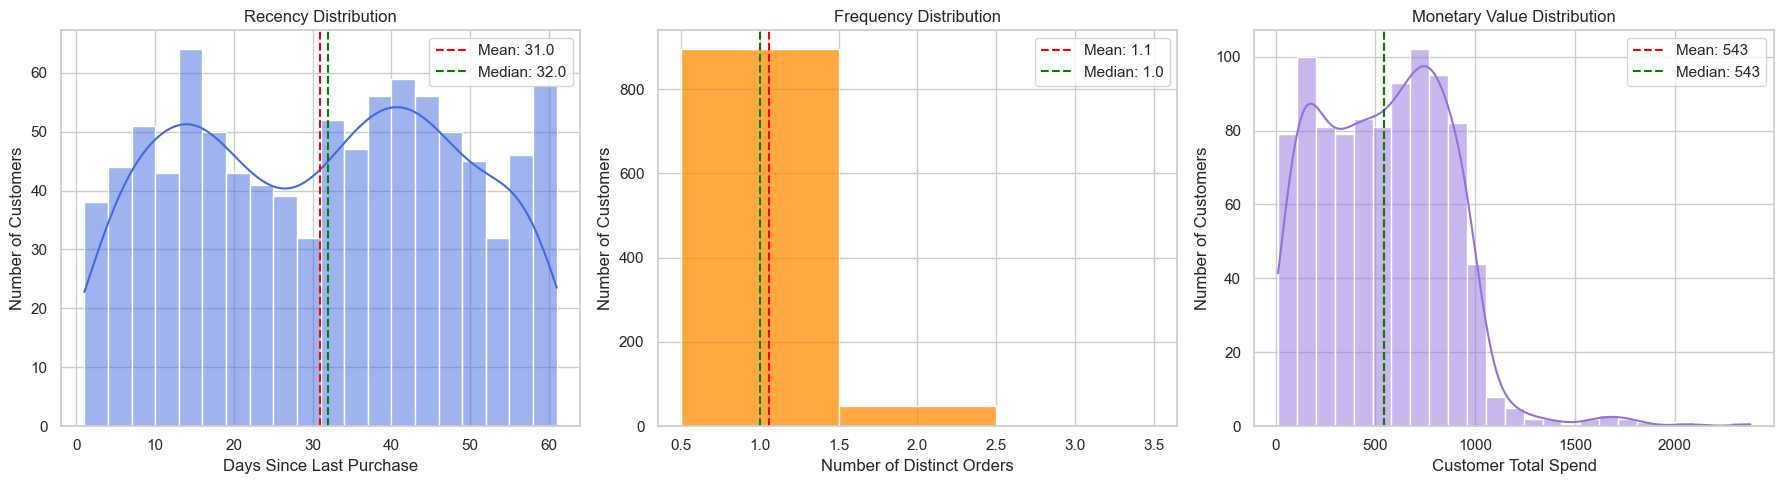

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Recency Distribution
sns.histplot(
    data=rfm,
    x="Recency",
    bins=20,
    kde=True,
    color="royalblue",
    ax=axes[0]
)

axes[0].axvline(
    rfm["Recency"].mean(),
    color="red",
    linestyle="--",
    label=f'Mean: {rfm["Recency"].mean():.1f}'
)

axes[0].axvline(
    rfm["Recency"].median(),
    color="green",
    linestyle="--",
    label=f'Median: {rfm["Recency"].median():.1f}'
)

axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")
axes[0].set_ylabel("Number of Customers")
axes[0].legend()


# 2. Frequency Distribution
sns.histplot(
    data=rfm,
    x="Frequency",
    discrete=True,
    color="darkorange",
    ax=axes[1]
)

axes[1].axvline(
    rfm["Frequency"].mean(),
    color="red",
    linestyle="--",
    label=f'Mean: {rfm["Frequency"].mean():.1f}'
)

axes[1].axvline(
    rfm["Frequency"].median(),
    color="green",
    linestyle="--",
    label=f'Median: {rfm["Frequency"].median():.1f}'
)

axes[1].set_title("Frequency Distribution")
axes[1].set_xlabel("Number of Distinct Orders")
axes[1].set_ylabel("Number of Customers")
axes[1].legend()


# 3. Monetary Value Distribution
sns.histplot(
    data=rfm,
    x="MonetaryValue",
    bins=25,
    kde=True,
    color="mediumpurple",
    ax=axes[2]
)

axes[2].axvline(
    rfm["MonetaryValue"].mean(),
    color="red",
    linestyle="--",
    label=f'Mean: {rfm["MonetaryValue"].mean():,.0f}'
)

axes[2].axvline(
    rfm["MonetaryValue"].median(),
    color="green",
    linestyle="--",
    label=f'Median: {rfm["MonetaryValue"].median():,.0f}'
)

axes[2].set_title("Monetary Value Distribution")
axes[2].set_xlabel("Customer Total Spend")
axes[2].set_ylabel("Number of Customers")
axes[2].legend()


# Improve layout
plt.tight_layout()
plt.show()

### Optional: Inspect score distributions

These plots show how the quantile scoring assigned customers to score levels. They are separate from the distributions of the underlying RFM metrics.

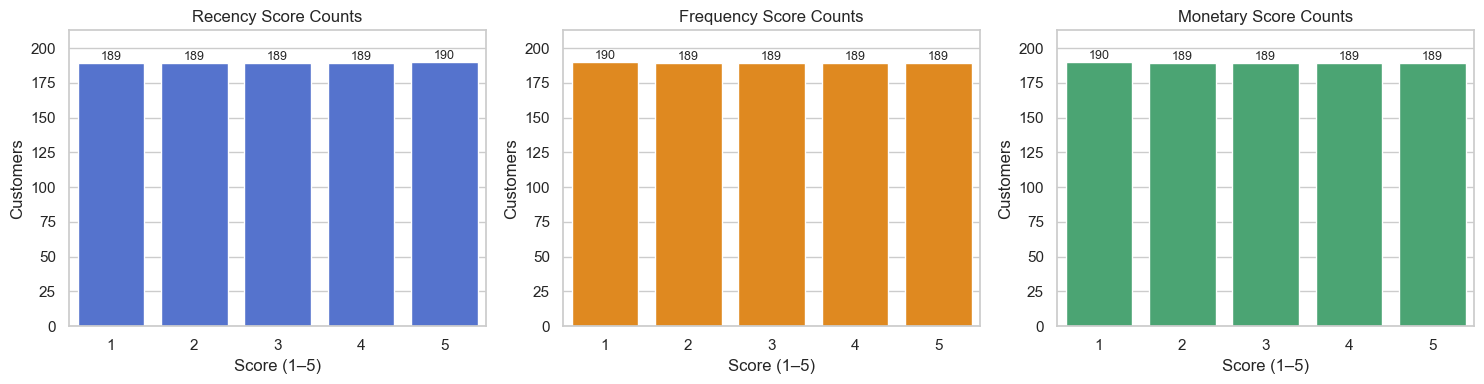

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Define a different color for each RFM score
score_colors = {
    "R_Score": "royalblue",
    "F_Score": "darkorange",
    "M_Score": "mediumseagreen"
}

# Define chart titles
score_titles = {
    "R_Score": "Recency Score Counts",
    "F_Score": "Frequency Score Counts",
    "M_Score": "Monetary Score Counts"
}

for ax, col in zip(
    axes,
    ["R_Score", "F_Score", "M_Score"]
):
    counts = rfm[col].value_counts().sort_index()

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        color=score_colors[col],
        ax=ax
    )

    # Add customer counts above the bars
    for i, value in enumerate(counts.values):
        ax.text(
            i,
            value,
            f"{value:,}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(score_titles[col], fontsize=12)
    ax.set_xlabel("Score (1–5)")
    ax.set_ylabel("Customers")

    # Add space above bars for the labels
    ax.set_ylim(0, counts.max() * 1.12)

plt.tight_layout()
plt.show()

## 12. Objective Task 10 — Top segments by customer count

The table is sorted by customer count and includes customer share and revenue share so that the largest segment is not automatically mistaken for the most valuable segment.

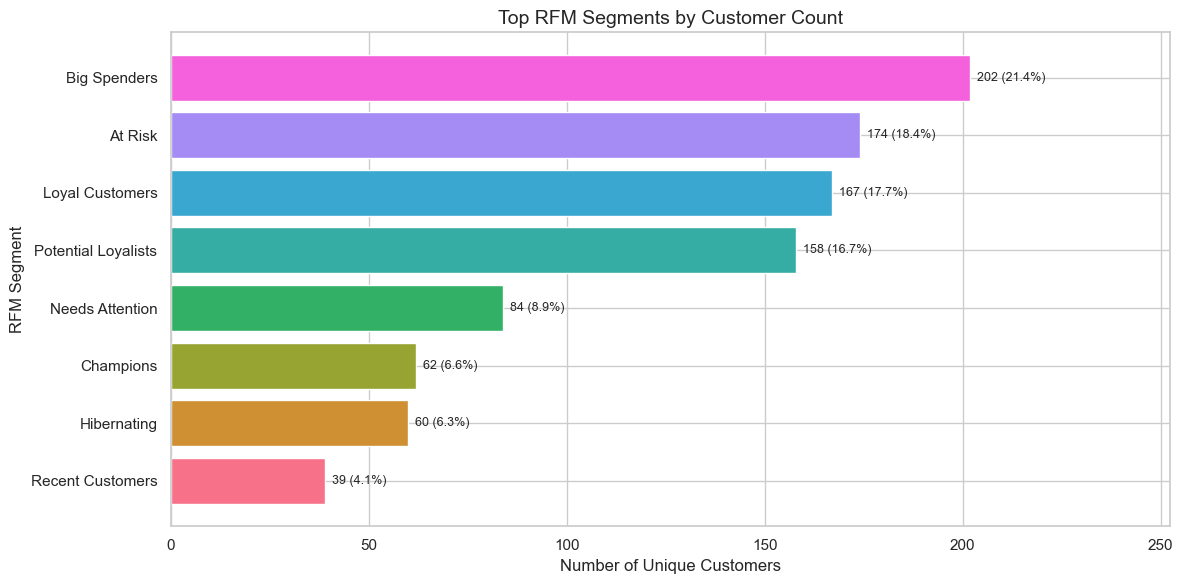

,Segment,Customers,Customer_Share_%,Revenue,Revenue_Share_%
4,Big Spenders,202,21.35,"168,616.47",32.83
5,At Risk,174,18.39,"64,484.01",12.55
1,Loyal Customers,167,17.65,"79,475.72",15.47
2,Potential Loyalists,158,16.70,"76,240.90",14.84
7,Needs Attention,84,8.88,"29,424.13",5.73
0,Champions,62,6.55,"60,727.81",11.82
6,Hibernating,60,6.34,"13,065.11",2.54
3,Recent Customers,39,4.12,"21,643.66",4.21


In [39]:
# Calculate customer count and share for each segment
segment_summary = (
    rfm.groupby("Segment", observed=False)
       .agg(
           Customers=("CustomerID", "nunique"),
           Revenue=("MonetaryValue", "sum")
       )
       .reset_index()
)

# Calculate customer share and revenue share
total_customers = segment_summary["Customers"].sum()
total_revenue = segment_summary["Revenue"].sum()

segment_summary["Customer_Share_%"] = (
    segment_summary["Customers"] / total_customers * 100
)

segment_summary["Revenue_Share_%"] = (
    segment_summary["Revenue"] / total_revenue * 100
    if total_revenue > 0
    else 0
)

# Select the top 10 segments by customer count
top_segments = (
    segment_summary
    .sort_values("Customers", ascending=False)
    .head(10)
    .sort_values("Customers", ascending=True)
)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top_segments["Segment"].astype(str),
    top_segments["Customers"],
    color=sns.color_palette("husl", n_colors=len(top_segments))
)

# Add customer counts and percentages to the bars
for bar, (_, row) in zip(bars, top_segments.iterrows()):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f'  {row["Customers"]:,} ({row["Customer_Share_%"]:.1f}%)',
        va="center",
        fontsize=9
    )

ax.set_title("Top RFM Segments by Customer Count", fontsize=14)
ax.set_xlabel("Number of Unique Customers")
ax.set_ylabel("RFM Segment")

# Add room for labels
ax.set_xlim(0, top_segments["Customers"].max() * 1.25)

plt.tight_layout()
plt.show()

# Display the supporting table
display(
    top_segments.sort_values("Customers", ascending=False)[
        ["Segment", "Customers", "Customer_Share_%", "Revenue", "Revenue_Share_%"]
    ].round(2)
)

## 13. Product analysis by RFM segment

The data contains four product labels. We connect transaction rows to each customer's RFM segment and calculate order count and revenue by product and segment.

,Segment,ProductInformation,Orders,Revenue,Average_Transaction
3,Champions,Product D,22,"16,885.10",767.50
2,Champions,Product C,23,"15,913.80",691.90
0,Champions,Product A,18,"14,700.34",816.69
1,Champions,Product B,21,"13,228.57",629.93
7,Loyal Customers,Product D,50,"23,036.82",460.74
6,Loyal Customers,Product C,50,"20,914.07",418.28
5,Loyal Customers,Product B,50,"20,250.47",405.01
4,Loyal Customers,Product A,37,"15,274.36",412.82
9,Potential Loyalists,Product B,43,"23,985.99",557.81
10,Potential Loyalists,Product C,43,"20,944.54",487.08


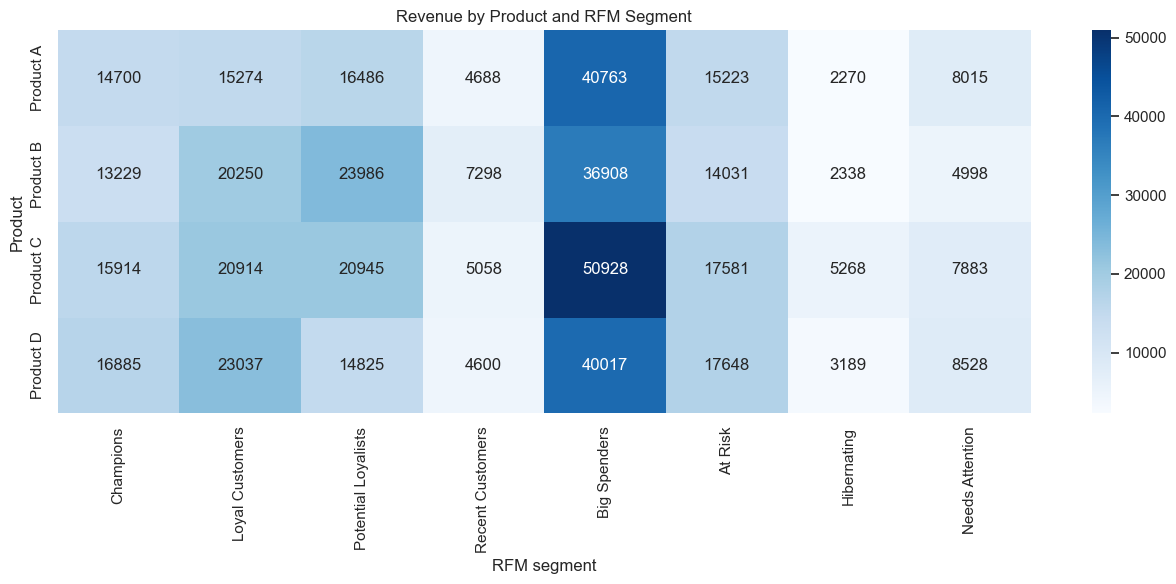

In [62]:
transaction_segments = data.merge(
    rfm[["CustomerID", "Segment", "R_Score", "F_Score", "M_Score"]],
    on="CustomerID",
    how="left",
    validate="many_to_one"
)

product_segment = (
    transaction_segments.groupby(["Segment", "ProductInformation"], observed=False)
    .agg(
        Orders=("OrderID", "nunique"),
        Revenue=("TransactionAmount", "sum"),
        Average_Transaction=("TransactionAmount", "mean"),
    )
    .reset_index()
)
display(product_segment.sort_values(["Segment", "Revenue"], ascending=[True, False]).head(30))

product_revenue_by_segment = product_segment.pivot(
    index="ProductInformation", columns="Segment", values="Revenue"
).fillna(0)

plt.figure(figsize=(13, 6))
sns.heatmap(product_revenue_by_segment, annot=True, fmt=".0f", cmap="Blues")
plt.title("Revenue by Product and RFM Segment")
plt.xlabel("RFM segment")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Section 14: Geographic RFM Analysis

,Location,Customers,Total_Revenue,Average_Revenue_Per_Customer,Average_Recency_Days,Average_Frequency,Customer_Share_%,Revenue_Share_%
3,Tokyo,259,"140,238.62",541.46,30.61,1.08,27.38,27.30
1,New York,233,"130,707.75",560.98,30.05,1.06,24.63,25.45
0,London,235,"130,667.25",556.03,30.76,1.05,24.84,25.44
2,Paris,219,"112,064.19",511.71,32.66,1.04,23.15,21.82


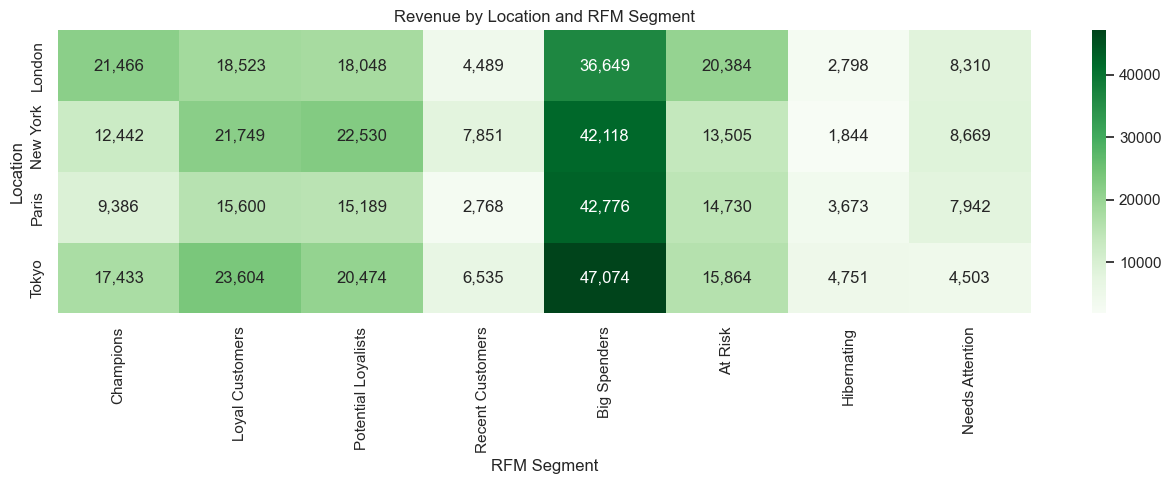

In [66]:
# Ensure CustomerID has the same data type in both DataFrames
data["CustomerID"] = data["CustomerID"].astype(str)
rfm["CustomerID"] = rfm["CustomerID"].astype(str)

# Map each customer to their most frequently observed location.
# If a customer has multiple locations, use revenue as a tie-breaker.
customer_location = (
    data.groupby(["CustomerID", "Location"], as_index=False)
        .agg(
            Orders=("OrderID", "nunique"),
            Revenue=("TransactionAmount", "sum")
        )
        .sort_values(
            ["CustomerID", "Orders", "Revenue"],
            ascending=[True, False, False]
        )
        .drop_duplicates("CustomerID")
        [["CustomerID", "Location"]]
)

# Combine customer locations with RFM metrics
customer_geo = rfm.merge(
    customer_location,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

# Summarise geographic customer value and engagement
geo_summary = (
    customer_geo.groupby("Location", dropna=False, observed=True)
        .agg(
            Customers=("CustomerID", "nunique"),
            Total_Revenue=("MonetaryValue", "sum"),
            Average_Revenue_Per_Customer=("MonetaryValue", "mean"),
            Average_Recency_Days=("Recency", "mean"),
            Average_Frequency=("Frequency", "mean")
        )
        .reset_index()
        .sort_values("Total_Revenue", ascending=False)
)

# Calculate customer share and revenue share by location
geo_summary["Customer_Share_%"] = (
    geo_summary["Customers"]
    / geo_summary["Customers"].sum()
    * 100
)

geo_summary["Revenue_Share_%"] = (
    geo_summary["Total_Revenue"]
    / geo_summary["Total_Revenue"].sum()
    * 100
)

display(geo_summary.round(2))


# Analyse revenue by geographic location and RFM segment
geo_segment = (
    customer_geo.groupby(
        ["Location", "Segment"],
        observed=True
    )
    .agg(
        Customers=("CustomerID", "nunique"),
        Revenue=("MonetaryValue", "sum")
    )
    .reset_index()
)

# Create a location-by-segment revenue matrix
geo_pivot = geo_segment.pivot(
    index="Location",
    columns="Segment",
    values="Revenue"
).fillna(0)

# Visualise revenue by location and RFM segment
plt.figure(figsize=(13, 5))

sns.heatmap(
    geo_pivot,
    annot=True,
    fmt=",.0f",
    cmap="Greens"
)

plt.title("Revenue by Location and RFM Segment")
plt.xlabel("RFM Segment")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

## 15. Time trends and seasonal limitations

The observed date range is short. We can describe patterns within the available period, but we cannot reliably establish annual seasonality from approximately two months of data.

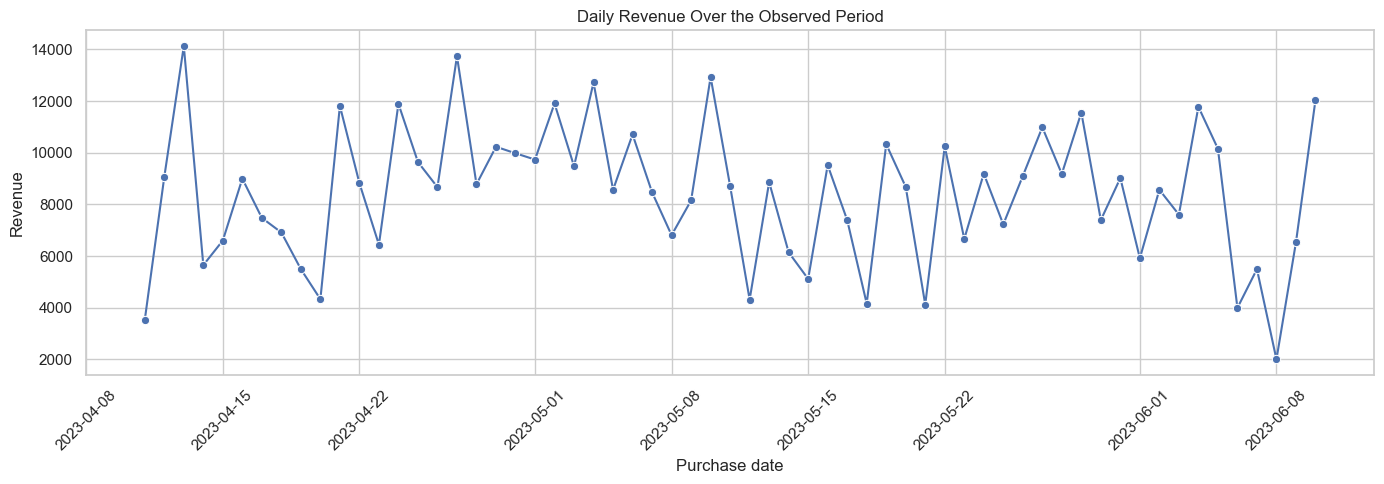

,YearMonth,Revenue,Orders
0,2023-04,"172,201.88",341
1,2023-05,"267,394.15",515
2,2023-06,"74,081.78",144


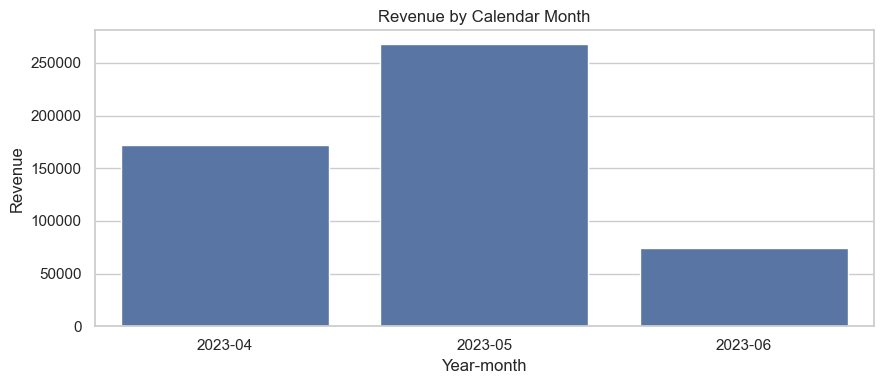

In [19]:
daily_revenue = (
    data.assign(PurchaseDay=data["PurchaseDate"].dt.normalize())
        .groupby("PurchaseDay", as_index=False)
        .agg(Revenue=("TransactionAmount", "sum"),
             Orders=("OrderID", "nunique"))
)

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=daily_revenue, x="PurchaseDay", y="Revenue", marker="o", ax=ax)
ax.set_title("Daily Revenue Over the Observed Period")
ax.set_xlabel("Purchase date")
ax.set_ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

monthly_revenue = (
    data.assign(YearMonth=data["PurchaseDate"].dt.to_period("M").astype(str))
        .groupby("YearMonth", as_index=False)
        .agg(Revenue=("TransactionAmount", "sum"),
             Orders=("OrderID", "nunique"))
)
display(monthly_revenue)

plt.figure(figsize=(9, 4))
sns.barplot(data=monthly_revenue, x="YearMonth", y="Revenue")
plt.title("Revenue by Calendar Month")
plt.xlabel("Year-month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

## 16. Subjective Question 1 — Identify potential churn and retain customers

### Data-Based Findings

The At Risk segment contains 174 customers, with an average recency of 49.14 days, average monetary value of 370.60, and total revenue of 64,484.01. The Hibernating segment contains 60 customers, with an average recency of 50.37 days, average monetary value of 217.75, and total revenue of 13,065.11. Both segments have an average purchase frequency of approximately one order per customer, suggesting limited repeat-purchase activity within the observed dataset.

### Recommended Interventions

1. **At Risk:** Test personalised reminders, relevant product recommendations and time-limited incentives to encourage repeat purchases.
2. **Hibernating:** Use low-cost win-back campaigns and evaluate customer responses before investing in larger discounts.
3. **Prioritise retention spending:** Assess campaign performance using reactivation rates, repeat purchases, incremental revenue and campaign costs.

### Limitation

The dataset covers a short transaction period and contains no explicit churn outcome. These segments indicate potential inactivity relative to the observed period, not confirmed customer churn. The recommended interventions should be tested before their effectiveness is assumed.

In [41]:
# Summarise only At Risk and Hibernating customers

churn_watch = (
    rfm[rfm["Segment"].isin(["At Risk", "Hibernating"])]
    .groupby("Segment", observed=True)
    .agg(
        Customers=("CustomerID", "nunique"),
        Average_Recency_Days=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary_Value=("MonetaryValue", "mean"),
        Total_Revenue=("MonetaryValue", "sum")
    )
    .reset_index()
)

display(churn_watch.round(2))

,Segment,Customers,Average_Recency_Days,Average_Frequency,Average_Monetary_Value,Total_Revenue
0,At Risk,174,49.14,1.01,370.60,"64,484.01"
1,Hibernating,60,50.37,1.00,217.75,"13,065.11"


## 17. Subjective Question 2 — Marketing strategies for each segment

Use the segment profile table to tailor marketing. These are recommendations to test, not claims that the campaigns will necessarily work.

| Segment | Suggested strategy | Primary measure |
|---|---|---|
| Champions | VIP access, loyalty recognition, early product access, premium service | Retention and repeat revenue |
| Loyal Customers | Loyalty rewards, replenishment reminders, referral invitations | Purchase frequency |
| Potential Loyalists | Onboarding, relevant recommendations, modest loyalty incentives | Second/third purchase conversion |
| Recent Customers | Welcome journey, product education, complementary recommendations | Second purchase rate |
| Big Spenders | Premium service, curated offers, early access | Repeat spend and retention |
| At Risk | Personalized win-back, feedback request, carefully controlled incentive | Reactivation rate |
| Hibernating | Low-cost reactivation and preference refresh; suppress if unresponsive | Incremental reactivation |
| Needs Attention | Test product relevance and messaging; use low-cost experiments | Conversion and cost per order |


In [44]:
# Calculate average customer spending for each RFM segment
avg_monetary = (
    rfm.groupby("Segment", observed=True)["MonetaryValue"]
       .mean()
       .rename("Avg_Monetary")
       .reset_index()
)

# Add the metric to the existing segment summary
segment_summary = segment_summary.drop(
    columns=["Avg_Monetary"],
    errors="ignore"
)

segment_summary = segment_summary.merge(
    avg_monetary,
    on="Segment",
    how="left"
)

display(segment_summary.round(2))

,Segment,Customers,Revenue,Customer_Share_%,Revenue_Share_%,Avg_Monetary
0,Champions,62,"60,727.81",6.55,11.82,979.48
1,Loyal Customers,167,"79,475.72",17.65,15.47,475.90
2,Potential Loyalists,158,"76,240.90",16.70,14.84,482.54
3,Recent Customers,39,"21,643.66",4.12,4.21,554.97
4,Big Spenders,202,"168,616.47",21.35,32.83,834.74
5,At Risk,174,"64,484.01",18.39,12.55,370.60
6,Hibernating,60,"13,065.11",6.34,2.54,217.75
7,Needs Attention,84,"29,424.13",8.88,5.73,350.29


In [45]:
# Build a marketing strategy table using the existing RFM segment summary

marketing_strategies = {
    "Champions": {
        "Strategy": "VIP rewards, exclusive offers, early product access and premium service",
        "Objective": "Recognise loyalty and encourage continued high-value purchases",
        "Success_Metric": "Repeat-purchase rate and revenue per customer"
    },
    "Loyal Customers": {
        "Strategy": "Loyalty rewards, personalised recommendations and referral invitations",
        "Objective": "Strengthen engagement and encourage repeat purchases",
        "Success_Metric": "Purchase frequency and repeat-purchase rate"
    },
    "Potential Loyalists": {
        "Strategy": "Relevant product recommendations, onboarding and modest loyalty incentives",
        "Objective": "Encourage customers to develop repeat-purchase habits",
        "Success_Metric": "Second- and third-purchase conversion"
    },
    "Recent Customers": {
        "Strategy": "Welcome campaigns, product guidance and complementary recommendations",
        "Objective": "Encourage first-time buyers to make another purchase",
        "Success_Metric": "Second-purchase rate"
    },
    "Big Spenders": {
        "Strategy": "Premium service, curated offers and early access to selected products",
        "Objective": "Protect revenue contribution and encourage continued engagement",
        "Success_Metric": "Repeat revenue and customer retention"
    },
    "At Risk": {
        "Strategy": "Personalised win-back messages, relevant recommendations and tested incentives",
        "Objective": "Re-engage customers whose purchasing activity may be declining",
        "Success_Metric": "Reactivation rate and incremental revenue"
    },
    "Hibernating": {
        "Strategy": "Low-cost reactivation campaigns and selective discounts",
        "Objective": "Test whether inactive customers can be reactivated economically",
        "Success_Metric": "Incremental reactivation and campaign cost"
    },
    "Needs Attention": {
        "Strategy": "Timely reminders, relevant product messaging and controlled promotions",
        "Objective": "Improve engagement before customers become less active",
        "Success_Metric": "Conversion rate and cost per reactivated customer"
    }
}

marketing_df = (
    pd.DataFrame.from_dict(marketing_strategies, orient="index")
    .rename_axis("Segment")
    .reset_index()
)

# Use the actual segment summary from the previous analysis
marketing_analysis = segment_summary.merge(
    marketing_df,
    on="Segment",
    how="left"
)

# Display the marketing analysis alongside actual customer metrics
display(
    marketing_analysis[
        [
            "Segment",
            "Customers",
            "Customer_Share_%",
            "Avg_Monetary",
            "Revenue",
            "Revenue_Share_%",
            "Strategy",
            "Objective",
            "Success_Metric"
        ]
    ]
    .sort_values("Revenue", ascending=False)
    .round(2)
)

,Segment,Customers,Customer_Share_%,Avg_Monetary,Revenue,Revenue_Share_%,Strategy,Objective,Success_Metric
4,Big Spenders,202,21.35,834.74,"168,616.47",32.83,"Premium service, curated offers and early acce...",Protect revenue contribution and encourage con...,Repeat revenue and customer retention
1,Loyal Customers,167,17.65,475.90,"79,475.72",15.47,"Loyalty rewards, personalised recommendations ...",Strengthen engagement and encourage repeat pur...,Purchase frequency and repeat-purchase rate
2,Potential Loyalists,158,16.70,482.54,"76,240.90",14.84,"Relevant product recommendations, onboarding a...",Encourage customers to develop repeat-purchase...,Second- and third-purchase conversion
5,At Risk,174,18.39,370.60,"64,484.01",12.55,"Personalised win-back messages, relevant recom...",Re-engage customers whose purchasing activity ...,Reactivation rate and incremental revenue
0,Champions,62,6.55,979.48,"60,727.81",11.82,"VIP rewards, exclusive offers, early product a...",Recognise loyalty and encourage continued high...,Repeat-purchase rate and revenue per customer
7,Needs Attention,84,8.88,350.29,"29,424.13",5.73,"Timely reminders, relevant product messaging a...",Improve engagement before customers become les...,Conversion rate and cost per reactivated customer
3,Recent Customers,39,4.12,554.97,"21,643.66",4.21,"Welcome campaigns, product guidance and comple...",Encourage first-time buyers to make another pu...,Second-purchase rate
6,Hibernating,60,6.34,217.75,"13,065.11",2.54,Low-cost reactivation campaigns and selective ...,Test whether inactive customers can be reactiv...,Incremental reactivation and campaign cost


### Interpretation and Recommendations

Big Spenders account for 21.35% of customers and contribute 32.83% of total revenue, making customer retention and personalised premium offers worthwhile strategies to test. Champions have the highest average monetary value (979.48), supporting targeted loyalty benefits and exclusive experiences. Loyal Customers and Potential Loyalists could benefit from personalised recommendations and initiatives encouraging repeat purchases. At Risk, Needs Attention and Hibernating customers may require targeted re-engagement, while Recent Customers should receive welcome communications that encourage a second purchase. Campaign effectiveness should be evaluated using repeat-purchase rates, incremental revenue and campaign costs rather than assuming that any strategy will automatically succeed.

## 18. Subjective Question 3 — Use product preferences to inform product development

The product-by-segment table shows which of the four product labels generate orders and revenue among each segment. Use those results to:
- Protect availability and visibility for products with strong demand from valuable segments.
- Test complementary recommendations for segments that purchase a given product frequently.
- Investigate products with low observed demand before changing or discontinuing them; low demand may reflect limited exposure rather than poor product quality.
- Collect product-level feedback, returns, feature usage and margin data before making feature-development decisions.

**Limitation:** The current `ProductInformation` values are generic labels. There are no product attributes or feature-level feedback fields, so this dataset cannot identify which specific features to improve.

In [49]:
product_segment_summary = (
    transaction_segments.groupby(["ProductInformation", "Segment"], observed=False)
    .agg(
        Orders=("OrderID", "nunique"),
        Revenue=("TransactionAmount", "sum"),
        Unique_Customers=("CustomerID", "nunique"),
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)
display(
    product_segment.sort_values(
        ["Segment", "Revenue"],
        ascending=[True, False]
    )
)

,Segment,ProductInformation,Orders,Revenue,Average_Transaction
3,Champions,Product D,22,"16,885.10",767.50
2,Champions,Product C,23,"15,913.80",691.90
0,Champions,Product A,18,"14,700.34",816.69
1,Champions,Product B,21,"13,228.57",629.93
7,Loyal Customers,Product D,50,"23,036.82",460.74
6,Loyal Customers,Product C,50,"20,914.07",418.28
5,Loyal Customers,Product B,50,"20,250.47",405.01
4,Loyal Customers,Product A,37,"15,274.36",412.82
9,Potential Loyalists,Product B,43,"23,985.99",557.81
10,Potential Loyalists,Product C,43,"20,944.54",487.08


### Interpretation and Recommendations

The product-by-segment table and *Revenue by Product and RFM Segment* heatmap in **Section 13 — Product Analysis by RFM Segment** show that leading products vary across RFM segments. Product D generates the highest revenue among Champions, Loyal Customers, At Risk and Needs Attention customers, while Product C leads among Big Spenders and Hibernating customers; Product B leads among Potential Loyalists and Recent Customers. These patterns can guide targeted product recommendations and help prioritise further demand and availability analysis. However, the dataset contains generic product labels without feature-level details or customer feedback, so specific product improvements cannot be determined directly. Further research using customer feedback, return records and product attributes is needed before making product-development decisions.

## 19. Subjective Question 4 — Geographic marketing

Use the geographic summary and location-by-segment heatmap to distinguish:
- Locations with high total revenue.
- Locations with high average revenue per customer.
- Locations with a large share of At Risk or Hibernating customers.
- Locations with many customers but comparatively low average spending.

**Recommendations:** Test localized product messaging and campaigns in high-value locations; use engagement-focused tests in lower-engagement locations. Compare results with a holdout group where feasible. Do not infer why a location performs differently without additional context such as local traffic, delivery times, campaign exposure, or customer demographics.

,Location,Customers,Total_Revenue,Average_Revenue_Per_Customer,Average_Recency_Days,Average_Frequency,Customer_Share_%,Revenue_Share_%
3,Tokyo,259,"140,238.62",541.46,30.61,1.08,27.38,27.30
1,New York,233,"130,707.75",560.98,30.05,1.06,24.63,25.45
0,London,235,"130,667.25",556.03,30.76,1.05,24.84,25.44
2,Paris,219,"112,064.19",511.71,32.66,1.04,23.15,21.82


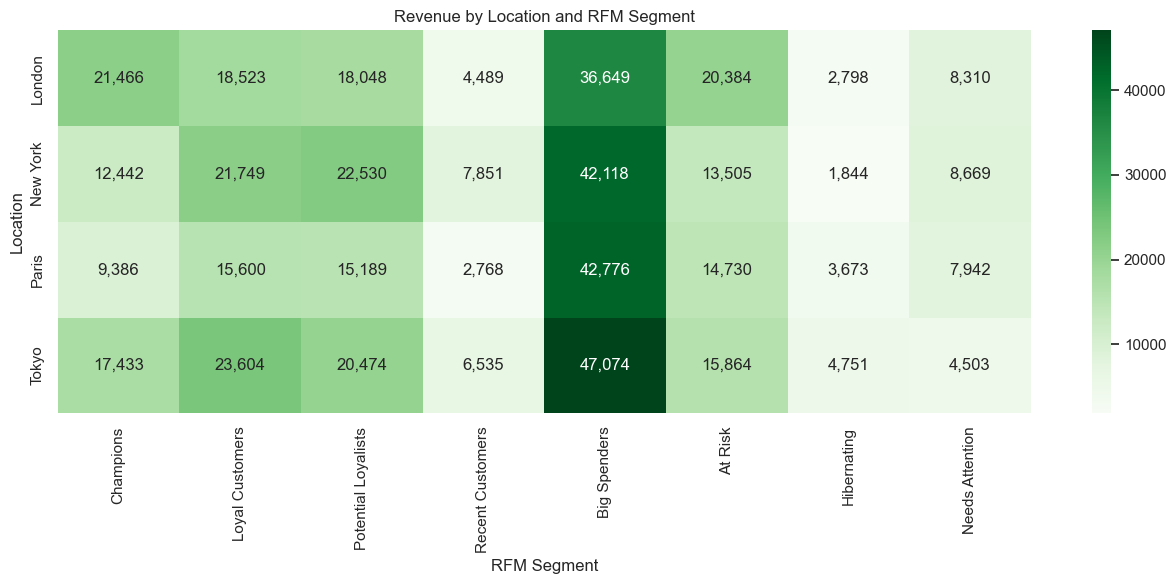

In [53]:
# Assign each customer a representative location.
# If a customer has multiple locations, select the location with
# the most distinct orders, using revenue to break ties.
# Standardise CustomerID data types before merging
data["CustomerID"] = data["CustomerID"].astype("string")
rfm["CustomerID"] = rfm["CustomerID"].astype("string")

customer_location = (
    data.groupby(["CustomerID", "Location"], as_index=False)
        .agg(
            Orders=("OrderID", "nunique"),
            Revenue=("TransactionAmount", "sum")
        )
        .sort_values(
            ["CustomerID", "Orders", "Revenue"],
            ascending=[True, False, False]
        )
        .drop_duplicates("CustomerID")
        [["CustomerID", "Location"]]
)

# Combine customer locations with RFM metrics
customer_geo = rfm.merge(
    customer_location,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

# Summarise geographic customer value and engagement
geo_summary = (
    customer_geo.groupby("Location", dropna=False, observed=True)
        .agg(
            Customers=("CustomerID", "nunique"),
            Total_Revenue=("MonetaryValue", "sum"),
            Average_Revenue_Per_Customer=("MonetaryValue", "mean"),
            Average_Recency_Days=("Recency", "mean"),
            Average_Frequency=("Frequency", "mean")
        )
        .reset_index()
        .sort_values("Total_Revenue", ascending=False)
)

# Calculate customer share and revenue share
total_customers = geo_summary["Customers"].sum()
total_revenue = geo_summary["Total_Revenue"].sum()

geo_summary["Customer_Share_%"] = (
    geo_summary["Customers"] / total_customers * 100
    if total_customers > 0 else 0
)

geo_summary["Revenue_Share_%"] = (
    geo_summary["Total_Revenue"] / total_revenue * 100
    if total_revenue > 0 else 0
)

display(geo_summary.round(2))


# Summarise revenue by location and RFM segment
geo_segment = (
    customer_geo.groupby(
        ["Location", "Segment"],
        observed=True,
        dropna=False
    )
    .agg(
        Customers=("CustomerID", "nunique"),
        Revenue=("MonetaryValue", "sum")
    )
    .reset_index()
)

# Create a location-by-segment revenue matrix
geo_pivot = (
    geo_segment.pivot(
        index="Location",
        columns="Segment",
        values="Revenue"
    )
    .fillna(0)
)

# Plot the heatmap
plt.figure(figsize=(13, 6))

sns.heatmap(
    geo_pivot,
    annot=True,
    fmt=",.0f",
    cmap="Greens"
)

plt.title("Revenue by Location and RFM Segment")
plt.xlabel("RFM Segment")
plt.ylabel("Location")
plt.tight_layout()-
plt.show()

### Interpretation and Recommendations

The geographic analysis shows that Tokyo contributes the highest total revenue (140,238.62; 27.30%), while New York has the highest average revenue per customer (560.98). Paris has the lowest total revenue and average revenue per customer among the four locations, making it a candidate for further investigation rather than automatically classifying it as a low-engagement region. The heatmap shows that Big Spenders are the leading revenue-generating segment in every location, supporting targeted retention campaigns and relevant premium offers. Marketing strategies should be tailored to regional customer value and RFM composition, with success measured through repeat purchases, reactivation rates and incremental revenue. These results are descriptive and do not establish the cause of regional differences or prove that a particular campaign will succeed.




## 20. Subjective Question 5 — Seasonal marketing

The dataset spans only April through June 2023. It supports analysis of daily and monthly patterns during that period, but it does **not** provide enough coverage to establish annual seasonality or confidently compare the same season across years.

**Recommended approach:**
1. Use daily revenue and order charts to identify short-term peaks within the observed period.
2. Compare daily trends by segment, while checking whether peaks are caused by a small number of large transactions.
3. For a genuine seasonal campaign plan, obtain at least 12–24 months of transaction history and relevant calendar events.
4. Run seasonal campaigns as controlled tests and measure incremental sales versus a baseline.

Treat any short-window pattern as exploratory rather than a reliable seasonal effect.

**Reference to Section 15:** The overall daily revenue trend in Section 15 provides the baseline for this analysis. The following visualisations extend that analysis by examining daily revenue and order activity across RFM segments and comparing monthly revenue contributions. This allows us to investigate segment-level patterns without duplicating the overall revenue chart.


In [58]:
# Create monthly revenue summary by RFM segment

monthly_segment_revenue = (
    seasonal_data.groupby(
        ["Purchase_Month", "Segment"],
        observed=True
    )
    .agg(
        Revenue=("TransactionAmount", "sum"),
        Orders=("OrderID", "nunique"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

# Count the number of observed purchase dates in each month
monthly_observation_days = (
    seasonal_data.groupby("Purchase_Month")["Purchase_Date"]
    .nunique()
    .rename("Observed_Days")
    .reset_index()
)

# Add the observation period to the monthly summary
monthly_segment_revenue = monthly_segment_revenue.merge(
    monthly_observation_days,
    on="Purchase_Month",
    how="left",
    validate="many_to_one"
)

# Calculate average daily revenue for comparison
monthly_segment_revenue["Revenue_Per_Observed_Day"] = (
    monthly_segment_revenue["Revenue"]
    / monthly_segment_revenue["Observed_Days"]
)

# Display the monthly results
display(
    monthly_segment_revenue.sort_values(
        ["Purchase_Month", "Revenue"],
        ascending=[True, False]
    ).round(2)
)

,Purchase_Month,Segment,Revenue,Orders,Customers,Observed_Days,Revenue_Per_Observed_Day
2,2023-04,Big Spenders,"94,402.81",122,116,20,"4,720.14"
3,2023-04,At Risk,"55,950.27",145,144,20,"2,797.51"
4,2023-04,Hibernating,"10,907.14",52,52,20,545.36
1,2023-04,Loyal Customers,"7,532.11",14,14,20,376.61
0,2023-04,Champions,"3,409.55",8,7,20,170.48
9,2023-05,Big Spenders,"74,213.66",90,90,31,"2,393.99"
6,2023-05,Loyal Customers,"60,178.16",139,135,31,"1,941.23"
7,2023-05,Potential Loyalists,"47,072.21",98,98,31,"1,518.46"
5,2023-05,Champions,"37,672.17",51,42,31,"1,215.23"
12,2023-05,Needs Attention,"29,424.13",84,84,31,949.17


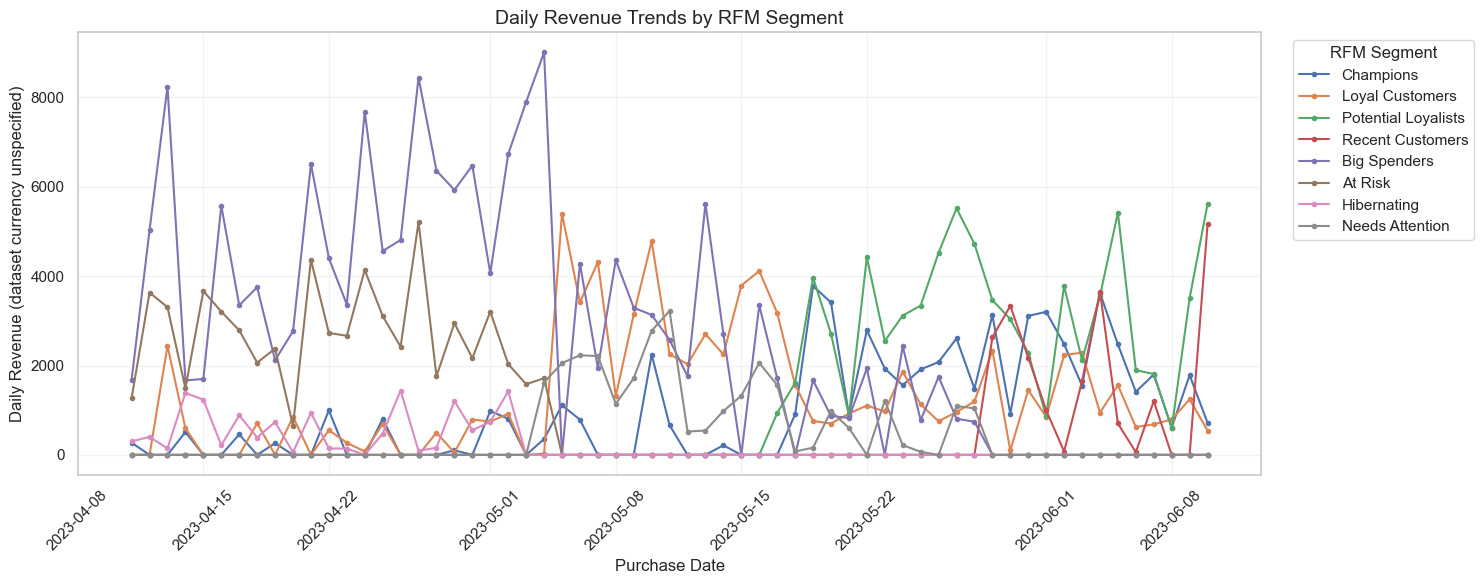

In [60]:
# Calculate daily revenue by RFM segment

daily_segment_revenue = (
    seasonal_data.groupby(
        ["Purchase_Date", "Segment"],
        observed=True
    )
    .agg(
        Revenue=("TransactionAmount", "sum"),
        Orders=("OrderID", "nunique")
    )
    .reset_index()
)

# Reshape the data for plotting
daily_revenue_pivot = daily_segment_revenue.pivot(
    index="Purchase_Date",
    columns="Segment",
    values="Revenue"
).fillna(0)

# Plot daily revenue trends
fig, ax = plt.subplots(figsize=(15, 6))

for segment in daily_revenue_pivot.columns:
    ax.plot(
        daily_revenue_pivot.index,
        daily_revenue_pivot[segment],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=segment
    )

ax.set_title("Daily Revenue Trends by RFM Segment", fontsize=14)
ax.set_xlabel("Purchase Date")
ax.set_ylabel("Daily Revenue (dataset currency unspecified)")
ax.tick_params(axis="x", rotation=45)

ax.legend(
    title="RFM Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

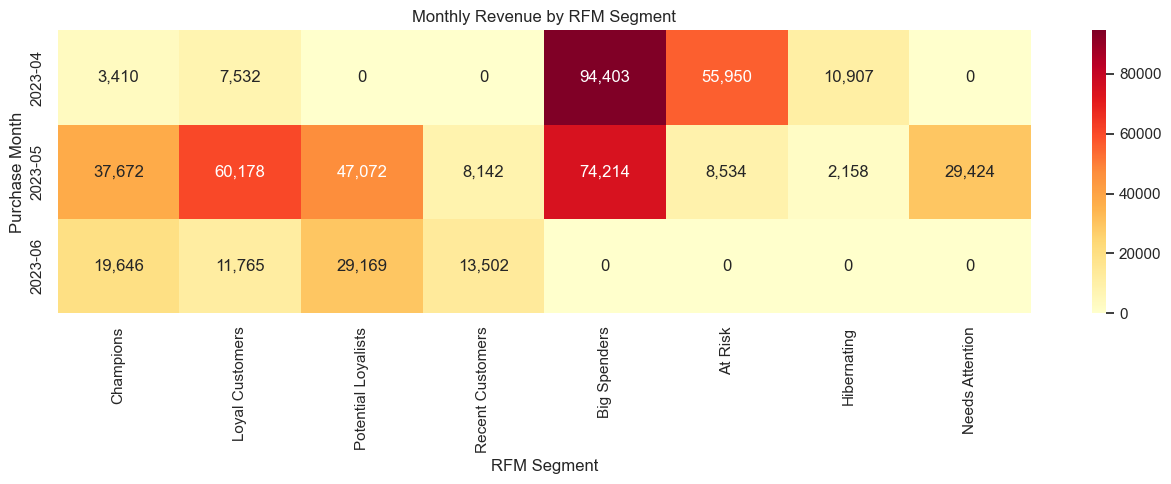

In [59]:
# Create a month-by-segment revenue matrix

monthly_revenue_heatmap = monthly_segment_revenue.pivot(
    index="Purchase_Month",
    columns="Segment",
    values="Revenue"
).fillna(0)

plt.figure(figsize=(13, 5))

sns.heatmap(
    monthly_revenue_heatmap,
    annot=True,
    fmt=",.0f",
    cmap="YlOrRd"
)

plt.title("Monthly Revenue by RFM Segment")
plt.xlabel("RFM Segment")
plt.ylabel("Purchase Month")

plt.tight_layout()
plt.show()

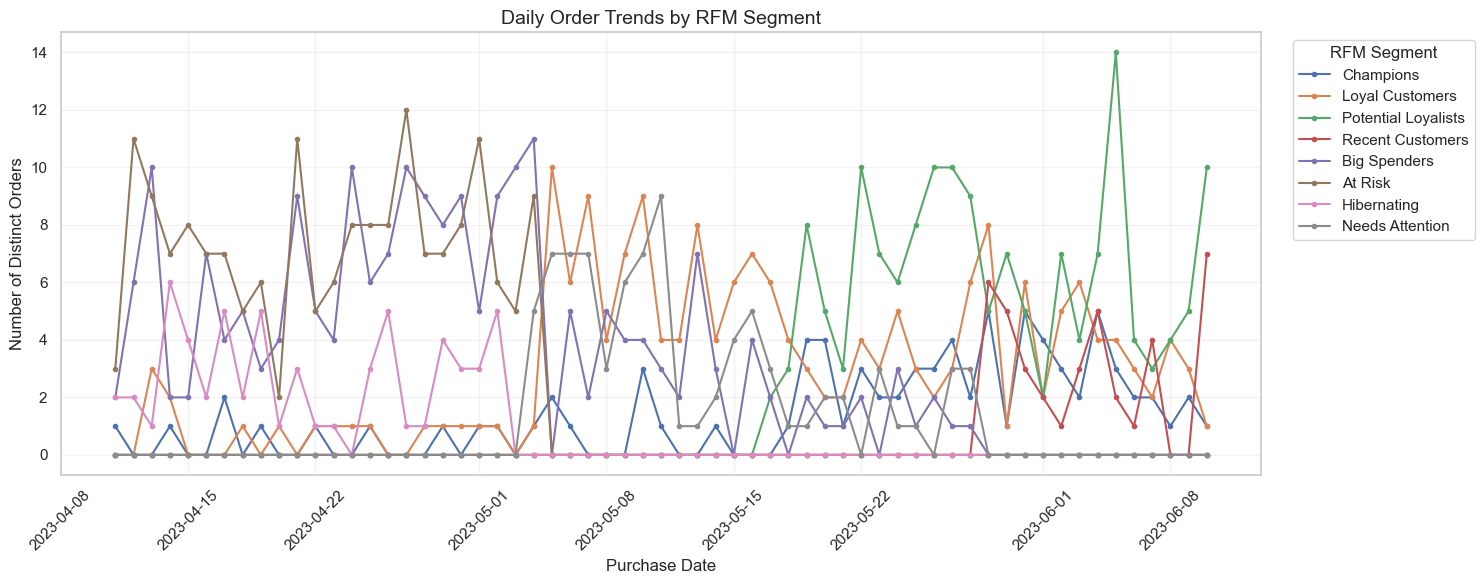

In [61]:
# Analyse daily order counts by RFM segment

daily_segment_orders = (
    seasonal_data.groupby(
        ["Purchase_Date", "Segment"],
        observed=True
    )
    .agg(
        Orders=("OrderID", "nunique"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

# Reshape the data for plotting
daily_orders_pivot = daily_segment_orders.pivot(
    index="Purchase_Date",
    columns="Segment",
    values="Orders"
).fillna(0)

# Plot daily order counts
fig, ax = plt.subplots(figsize=(15, 6))

for segment in daily_orders_pivot.columns:
    ax.plot(
        daily_orders_pivot.index,
        daily_orders_pivot[segment],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=segment
    )

ax.set_title("Daily Order Trends by RFM Segment", fontsize=14)
ax.set_xlabel("Purchase Date")
ax.set_ylabel("Number of Distinct Orders")
ax.tick_params(axis="x", rotation=45)

ax.legend(
    title="RFM Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation and Recommendations

The daily revenue and order-count charts show considerable variation in purchasing activity across RFM segments during the observed period. Big Spenders generate several of the largest revenue peaks, particularly in April and early May, while Potential Loyalists display more frequent order activity during parts of late May and early June. These patterns suggest opportunities to test premium promotions for Big Spenders and repeat-purchase campaigns for Potential Loyalists. Targeted re-engagement campaigns could also be tested for At Risk and Hibernating customers.

Comparing revenue with order counts helps distinguish periods of higher purchasing activity from revenue peaks that may be driven by a small number of high-value transactions. The monthly summary and heatmap provide an additional comparison of revenue contributions across segments. However, April and June contain incomplete observation periods, so monthly revenue totals should not be compared without considering the number of observed days.

The dataset covers only April 11 to June 10, 2023, and therefore cannot establish reliable annual seasonality or recurring holiday-related purchasing peaks. Furthermore, RFM segments are calculated using the entire observation period and applied retrospectively to historical transactions. The findings should be treated as exploratory evidence for campaign planning rather than proof of predictable seasonal behaviour. Future campaigns should be tested against a suitable baseline and evaluated using incremental revenue, order counts, repeat-purchase rates and campaign costs.


## 21. Subjective Question 6 — Cross-selling and bundled offers

The current dataset has one row per unique order and each order has a single product label. Therefore, it does not directly reveal which products were bought together in the same basket. Reliable market-basket analysis and observed product-pair recommendations cannot be calculated from this structure.

**What can be done with current data:** Identify products that perform well within each RFM segment and test complementary offers as hypotheses. For example, show a related product to customers who bought a popular item, then measure conversion.

**What additional data is needed:** A transaction-line dataset with multiple product rows per `OrderID`, product identifiers, quantities and prices. With that data, we could calculate product-pair frequency or association rules and build evidence-based bundles.

In [22]:
# Verify whether multi-product baskets exist in the supplied data.
products_per_order = data.groupby("OrderID")["ProductInformation"].nunique()
print("Orders containing more than one distinct product:",
      int((products_per_order > 1).sum()))
print("Maximum distinct products per order:", int(products_per_order.max()))

if products_per_order.max() <= 1:
    print(
        "Conclusion: this dataset does not contain multi-product baskets, "
        "so observed product co-purchase / association-rule analysis is not possible."
    )

Orders containing more than one distinct product: 0
Maximum distinct products per order: 1
Conclusion: this dataset does not contain multi-product baskets, so observed product co-purchase / association-rule analysis is not possible.


In [68]:
# Analyse product popularity within each RFM segment

segment_product_analysis = (
    transaction_segments
    .groupby(["Segment", "ProductInformation"], observed=True)
    .agg(
        Unique_Customers=("CustomerID", "nunique"),
        Orders=("OrderID", "nunique"),
        Total_Revenue=("TransactionAmount", "sum"),
        Average_Transaction_Value=("TransactionAmount", "mean")
    )
    .reset_index()
)

# Calculate the total number of unique customers in each segment
segment_customer_counts = (
    transaction_segments
    .groupby("Segment", observed=True)["CustomerID"]
    .nunique()
)

# Map segment customer counts to the product summary
segment_product_analysis["Segment_Customers"] = (
    segment_product_analysis["Segment"]
    .astype(str)
    .map(segment_customer_counts.rename_axis("Segment").to_dict())
)

# Ensure the columns used in the calculation are numeric
segment_product_analysis["Unique_Customers"] = pd.to_numeric(
    segment_product_analysis["Unique_Customers"]
)

segment_product_analysis["Segment_Customers"] = pd.to_numeric(
    segment_product_analysis["Segment_Customers"]
)

# Calculate the percentage of customers in each segment
# who have purchased each product
segment_product_analysis["Customer_Penetration_Pct"] = (
    segment_product_analysis["Unique_Customers"]
    / segment_product_analysis["Segment_Customers"]
    * 100
)

# Sort products by customer penetration within each segment
segment_product_analysis = segment_product_analysis.sort_values(
    ["Segment", "Customer_Penetration_Pct", "Total_Revenue"],
    ascending=[True, False, False]
)

display(segment_product_analysis.round(2))

,Segment,ProductInformation,Unique_Customers,Orders,Total_Revenue,Average_Transaction_Value,Segment_Customers,Customer_Penetration_Pct
3,Champions,Product D,21,22,"16,885.10",767.50,62,33.87
2,Champions,Product C,20,23,"15,913.80",691.90,62,32.26
1,Champions,Product B,20,21,"13,228.57",629.93,62,32.26
0,Champions,Product A,18,18,"14,700.34",816.69,62,29.03
7,Loyal Customers,Product D,50,50,"23,036.82",460.74,167,29.94
5,Loyal Customers,Product B,48,50,"20,250.47",405.01,167,28.74
6,Loyal Customers,Product C,47,50,"20,914.07",418.28,167,28.14
4,Loyal Customers,Product A,37,37,"15,274.36",412.82,167,22.16
9,Potential Loyalists,Product B,43,43,"23,985.99",557.81,158,27.22
10,Potential Loyalists,Product C,43,43,"20,944.54",487.08,158,27.22


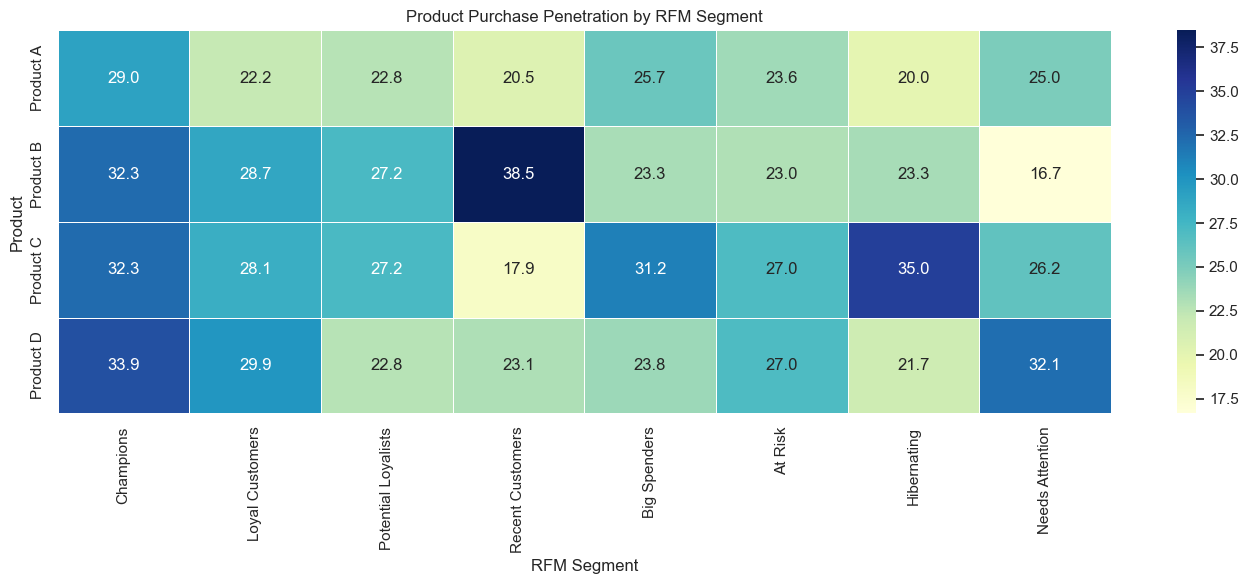

In [69]:
# Prepare data for the heatmap

penetration_pivot = segment_product_analysis.pivot(
    index="ProductInformation",
    columns="Segment",
    values="Customer_Penetration_Pct"
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    penetration_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Product Purchase Penetration by RFM Segment")
plt.xlabel("RFM Segment")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [70]:
# Create a set of products previously purchased by each customer

customer_products = (
    transaction_segments
    .groupby("CustomerID")["ProductInformation"]
    .agg(lambda products: set(products.dropna()))
)

# Retrieve each customer's RFM segment
customer_segments = (
    rfm[["CustomerID", "Segment"]]
    .drop_duplicates(subset="CustomerID")
    .set_index("CustomerID")["Segment"]
)

# Identify all available products
all_products = set(
    transaction_segments["ProductInformation"].dropna().unique()
)

# Identify products not yet purchased by each customer
customer_product_gaps = []

for customer_id, purchased_products in customer_products.items():

    segment = customer_segments.get(customer_id)

    unpurchased_products = all_products - purchased_products

    for product in unpurchased_products:
        customer_product_gaps.append({
            "CustomerID": customer_id,
            "Segment": segment,
            "Previously_Purchased_Products": ", ".join(
                sorted(purchased_products)
            ),
            "Potential_Recommendation": product
        })

customer_product_gaps = pd.DataFrame(customer_product_gaps)

display(customer_product_gaps.head(20))

,CustomerID,Segment,Previously_Purchased_Products,Potential_Recommendation
0,1011,Loyal Customers,Product B,Product A
1,1011,Loyal Customers,Product B,Product C
2,1011,Loyal Customers,Product B,Product D
3,1025,Needs Attention,Product D,Product A
4,1025,Needs Attention,Product D,Product C
5,1025,Needs Attention,Product D,Product B
6,1029,Recent Customers,Product D,Product A
7,1029,Recent Customers,Product D,Product C
8,1029,Recent Customers,Product D,Product B
9,1046,Big Spenders,Product B,Product A


In [71]:
# Rank potential products using customer penetration within each segment

product_rankings = segment_product_analysis.sort_values(
    ["Segment", "Customer_Penetration_Pct", "Total_Revenue"],
    ascending=[True, False, False]
)

# Build a ranked list of candidate products for each segment
segment_recommendations = {}

for segment, group in product_rankings.groupby("Segment", observed=False):

    segment_recommendations[segment] = (
        group["ProductInformation"].tolist()
    )

# Generate recommendations for individual customers
recommendation_rows = []

for customer_id, purchased_products in customer_products.items():

    segment = customer_segments.get(customer_id)

    ranked_products = segment_recommendations.get(segment, [])

    # Recommend products the customer has not purchased
    candidates = [
        product
        for product in ranked_products
        if product not in purchased_products
    ]

    for rank, product in enumerate(candidates[:2], start=1):

        recommendation_rows.append({
            "CustomerID": customer_id,
            "Segment": segment,
            "Recommendation_Rank": rank,
            "Recommended_Product": product,
            "Previously_Purchased_Products": ", ".join(
                sorted(purchased_products)
            )
        })

cross_sell_recommendations = pd.DataFrame(recommendation_rows)

display(cross_sell_recommendations.head(30))

,CustomerID,Segment,Recommendation_Rank,Recommended_Product,Previously_Purchased_Products
0,1011,Loyal Customers,1,Product D,Product B
1,1011,Loyal Customers,2,Product C,Product B
2,1025,Needs Attention,1,Product C,Product D
3,1025,Needs Attention,2,Product A,Product D
4,1029,Recent Customers,1,Product B,Product D
5,1029,Recent Customers,2,Product A,Product D
6,1046,Big Spenders,1,Product C,Product B
7,1046,Big Spenders,2,Product A,Product B
8,1049,Needs Attention,1,Product D,Product A
9,1049,Needs Attention,2,Product C,Product A


In [72]:
# Summarise potential cross-selling opportunities by segment

cross_sell_summary = (
    cross_sell_recommendations
    .groupby("Segment", observed=False)
    .agg(
        Potential_Recommendations=("CustomerID", "size"),
        Customers_With_Recommendations=("CustomerID", "nunique")
    )
    .reset_index()
)

display(cross_sell_summary)

,Segment,Potential_Recommendations,Customers_With_Recommendations
0,At Risk,348,174
1,Big Spenders,404,202
2,Champions,124,62
3,Hibernating,120,60
4,Loyal Customers,333,167
5,Needs Attention,168,84
6,Potential Loyalists,316,158
7,Recent Customers,78,39


### Interpretation of Cross-Selling Analysis

**Key findings**

The product penetration analysis identified the leading product within each RFM segment:

* Champions: Product D (33.87% penetration).
* Loyal Customers: Product D (29.94%).
* Potential Loyalists: Products B and C (27.22% each).
* Recent Customers: Product B (38.46%).
* Big Spenders: Product C (31.19%).
* At Risk: Products C and D (27.01% each).
* Hibernating: Product C (35.00%).
* Needs Attention: Product D (32.14%).

The customer-level recommendation analysis generated 1,891 potential customer-product recommendations across 946 customers. Big Spenders had 404 recommendations, followed by At Risk customers (348), Loyal Customers (333) and Potential Loyalists (316).

**Business interpretation**

Product penetration and revenue contribution can help identify products worth testing in segment-specific recommendation campaigns. Customer-level purchase history can also be used to identify products that an individual has not purchased and rank them using product popularity within the customer's RFM segment.

These recommendations are candidates for experimentation. They do not establish that the products are complementary or that customers will purchase them.

**Limitations and additional data required**

The dataset contains one product label per order. Validation confirmed that zero orders contain more than one distinct product and the maximum number of distinct products per order is one. Therefore, product co-purchase frequencies and association rules cannot be calculated from the current dataset.

A transaction-line dataset containing multiple product records per order, product identifiers, quantities and prices would enable direct product-pair analysis and support more reliable bundle recommendations.

Recommendation effectiveness should be evaluated using conversion rates, repeat purchases, average order value, incremental revenue and profitability. A control group should be used where feasible.

**Conclusion**

The current analysis provides a baseline method for identifying potential product recommendations by RFM segment. Actual cross-selling relationships and the commercial effectiveness of proposed bundles require additional transaction data and experimental validation.


## 22. Subjective Question 7 — Indirect feedback, repeat purchases and returns

### Interpretation and Limitations

The repeat-purchase analysis compares customer purchasing behaviour across RFM segments by measuring the proportion of customers with multiple distinct orders, average orders per customer and average spending per customer.

Customers with repeated purchases demonstrate continued purchasing activity during the observed period. Customers who previously purchased multiple times but have not purchased recently may warrant further investigation and targeted retention efforts.

However, repeat purchases do not independently establish customer satisfaction, and a lack of repeat purchases does not necessarily indicate dissatisfaction.

The current dataset does not contain product returns, refund records, return reasons, customer ratings, reviews or complaints. Therefore, return rates and direct measures of customer satisfaction cannot be calculated.

To strengthen the analysis, future data collection should include return information linked to customers, orders and products, alongside customer reviews or survey responses. These additional indicators could help distinguish purchasing activity from potential product or service concerns.

**Conclusion:** Repeat-purchase behaviour provides a useful indirect measure of customer engagement. Combining it with RFM segmentation can help prioritise retention efforts, but additional return and customer feedback data would be required to assess customer satisfaction more directly.


In [74]:
# Analyse repeat-purchase behaviour across RFM segments

# Calculate the number of distinct orders per customer
customer_purchase_history = (
    transaction_segments
    .groupby("CustomerID")
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Total_Spending=("TransactionAmount", "sum"),
        Most_Recent_Purchase=("PurchaseDate", "max")
    )
    .reset_index()
)

# Merge each customer's RFM segment
customer_purchase_history = customer_purchase_history.merge(
    rfm[["CustomerID", "Segment"]],
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

# Identify customers with repeat purchases
customer_purchase_history["Repeat_Customer"] = (
    customer_purchase_history["Total_Orders"] > 1
)

# Summarise repeat-purchase behaviour by RFM segment
repeat_purchase_summary = (
    customer_purchase_history
    .groupby("Segment", observed=True)
    .agg(
        Customers=("CustomerID", "nunique"),
        Repeat_Customers=("Repeat_Customer", "sum"),
        Average_Orders_Per_Customer=("Total_Orders", "mean"),
        Average_Spending_Per_Customer=("Total_Spending", "mean")
    )
    .reset_index()
)

# Calculate repeat-purchase rate within each segment
repeat_purchase_summary["Repeat_Purchase_Rate_Pct"] = (
    repeat_purchase_summary["Repeat_Customers"]
    / repeat_purchase_summary["Customers"]
    * 100
)

# Sort segments by repeat-purchase rate
repeat_purchase_summary = repeat_purchase_summary.sort_values(
    "Repeat_Purchase_Rate_Pct",
    ascending=False
)

display(repeat_purchase_summary.round(2))

,Segment,Customers,Repeat_Customers,Average_Orders_Per_Customer,Average_Spending_Per_Customer,Repeat_Purchase_Rate_Pct
0,Champions,62,21,1.35,979.48,33.87
1,Loyal Customers,167,19,1.12,475.90,11.38
4,Big Spenders,202,9,1.05,834.74,4.46
5,At Risk,174,2,1.01,370.60,1.15
3,Recent Customers,39,0,1.00,554.97,0.00
2,Potential Loyalists,158,0,1.00,482.54,0.00
6,Hibernating,60,0,1.00,217.75,0.00
7,Needs Attention,84,0,1.00,350.29,0.00


### Interpretation of Results

The repeat-purchase analysis reveals differences in customer purchasing behaviour across RFM segments.

* **Champions** have the highest repeat-purchase rate at 33.87% (21 out of 62 customers).
* **Loyal Customers** follow with a repeat-purchase rate of 11.38% (19 out of 167 customers).
* **Big Spenders** have a low repeat-purchase rate of 4.46%, despite the highest average spending per customer of 834.74.
* **At Risk** customers have a repeat-purchase rate of just 1.15%, while the remaining four segments show no repeat purchases during the observed period.

### Business Implications

Champions could be targeted with loyalty initiatives, while personalised recommendations could encourage additional purchases among Big Spenders. Re-engagement campaigns could be tested for At Risk customers.

**Limitation:** Repeat purchasing is an indirect indicator of customer behaviour, not definitive evidence of satisfaction. The dataset contains no return records or direct customer feedback, so these factors cannot be analysed.

**Conclusion:** Combining repeat-purchase behaviour with RFM segmentation can help prioritise retention strategies. Longer-term transaction data, product return records and direct customer feedback would be needed to assess customer satisfaction more comprehensively.


## 23. Subjective Question 8 — Revenue variation by weekday and RFM segment

We attach the customer segment to each transaction and compare total revenue, order count and average revenue per observed calendar day by weekday. Total revenue alone may be affected by the number of observed dates or transactions, so the daily average is also shown.

,Segment,Weekday,Revenue,Orders,Active_Dates,Revenue_Per_Observed_Day
0,Champions,Monday,"9,829.50",14,5,"1,965.90"
1,Champions,Tuesday,"6,154.28",8,6,"1,025.71"
2,Champions,Wednesday,"8,972.24",13,5,"1,794.45"
3,Champions,Thursday,"7,649.34",11,6,"1,274.89"
4,Champions,Friday,"11,739.74",15,6,"1,956.62"
5,Champions,Saturday,"10,170.90",14,7,"1,452.99"
6,Champions,Sunday,"6,211.81",9,4,"1,552.95"
7,Loyal Customers,Monday,"10,922.02",28,7,"1,560.29"
8,Loyal Customers,Tuesday,"11,273.68",24,8,"1,409.21"
9,Loyal Customers,Wednesday,"11,951.86",28,5,"2,390.37"


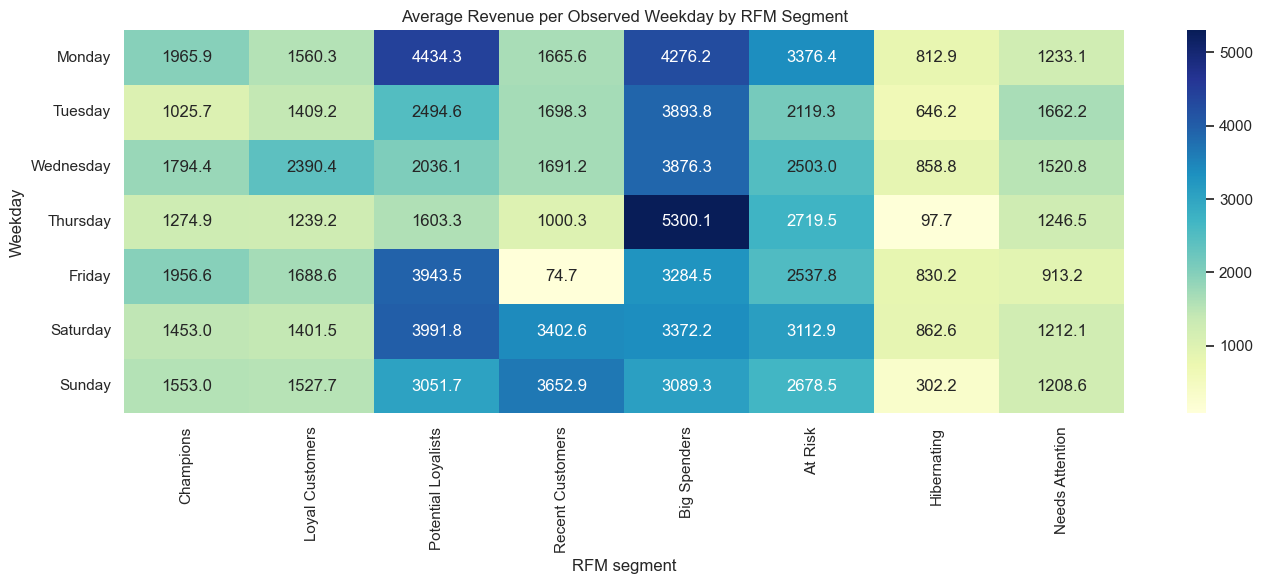

In [23]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_data = transaction_segments.copy()
weekday_data["PurchaseDay"] = weekday_data["PurchaseDate"].dt.normalize()
weekday_data["Weekday"] = pd.Categorical(
    weekday_data["PurchaseDate"].dt.day_name(),
    categories=weekday_order,
    ordered=True
)

weekday_segment_summary = (
    weekday_data.groupby(["Segment", "Weekday"], observed=False)
    .agg(
        Revenue=("TransactionAmount", "sum"),
        Orders=("OrderID", "nunique"),
        Active_Dates=("PurchaseDay", "nunique"),
    )
    .reset_index()
)
weekday_segment_summary["Revenue_Per_Observed_Day"] = (
    weekday_segment_summary["Revenue"]
    / weekday_segment_summary["Active_Dates"].replace(0, np.nan)
)
display(weekday_segment_summary.sort_values(["Segment", "Weekday"]).round(2))

weekday_pivot = weekday_segment_summary.pivot(
    index="Weekday", columns="Segment", values="Revenue_Per_Observed_Day"
).reindex(weekday_order)

plt.figure(figsize=(14, 6))
sns.heatmap(weekday_pivot, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average Revenue per Observed Weekday by RFM Segment")
plt.xlabel("RFM segment")
plt.ylabel("Weekday")
plt.tight_layout()
plt.show()

### Interpretation of Results

The weekday analysis reveals differences in average daily revenue across RFM segments.

* **Champions:** Monday and Friday record the highest average daily revenue, at 1,965.90 and 1,956.62, respectively.
* **Loyal Customers:** Wednesday records the highest average daily revenue at 2,390.37.
* **Potential Loyalists:** Monday leads at 4,434.29.
* **Recent Customers:** Weekend revenue appears relatively high, but the small number of observed dates limits the reliability of this pattern.
* **Big Spenders:** Thursday records the highest average daily revenue at 5,300.10.
* **At Risk:** Monday leads at 3,376.39.
* **Hibernating:** Wednesday records the highest average daily revenue at 858.81.
* **Needs Attention:** Tuesday leads at 1,662.23.

### Business Implications

These patterns can inform experiments with campaign timing, promotional messages and customer engagement. For example, campaigns targeting Big Spenders could test Thursday delivery, while campaigns for Potential Loyalists could test Monday delivery.

**Limitation:** The dataset covers a short period, and the number of observed dates varies across weekdays and segments. These findings do not establish a consistent weekday preference or prove that campaign timing causes higher revenue.

### Conclusion

Weekday revenue analysis provides an initial basis for testing segment-specific campaign timing. Longer-term transaction data and controlled experiments are needed to confirm whether these patterns persist and whether adjusting campaign timing improves revenue.


## 24. Executive summary tables

These tables provide a compact view of customer value and segment composition for the final report and presentation.

In [24]:
executive_summary = segment_summary.copy()
executive_summary["Revenue_Per_Customer"] = (
    executive_summary["Revenue"] / executive_summary["Customers"].replace(0, np.nan)
)
executive_summary = executive_summary[
    [
        "Segment", "Customers", "Customer_Share_%", "Revenue",
        "Revenue_Share_%", "Average_Recency_Days", "Average_Frequency",
        "Average_Monetary_Value", "Revenue_Per_Customer"
    ]
].sort_values("Revenue", ascending=False)

display(executive_summary.round(2))

best_revenue_segment = executive_summary.iloc[0]["Segment"] if len(executive_summary) else "N/A"
largest_segment = (
    executive_summary.sort_values("Customers", ascending=False).iloc[0]["Segment"]
    if len(executive_summary) else "N/A"
)
print(f"Segment with the highest total observed revenue: {best_revenue_segment}")
print(f"Largest segment by customer count: {largest_segment}")

,Segment,Customers,Customer_Share_%,Revenue,Revenue_Share_%,Average_Recency_Days,Average_Frequency,Average_Monetary_Value,Revenue_Per_Customer
4,Big Spenders,202,21.35,"168,616.47",32.83,42.19,1.05,834.74,834.74
1,Loyal Customers,167,17.65,"79,475.72",15.47,21.63,1.12,475.90,475.90
2,Potential Loyalists,158,16.70,"76,240.90",14.84,12.71,1.00,482.54,482.54
5,At Risk,174,18.39,"64,484.01",12.55,49.14,1.01,370.60,370.60
0,Champions,62,6.55,"60,727.81",11.82,13.02,1.35,979.48,979.48
7,Needs Attention,84,8.88,"29,424.13",5.73,29.63,1.00,350.29,350.29
3,Recent Customers,39,4.12,"21,643.66",4.21,7.67,1.00,554.97,554.97
6,Hibernating,60,6.34,"13,065.11",2.54,50.37,1.00,217.75,217.75


Segment with the highest total observed revenue: Big Spenders
Largest segment by customer count: Big Spenders


## 25. Save analysis outputs

The following files are exported for reuse in the written report or presentation. They are saved in the notebook's current working directory.

In [25]:
OUTPUT_DIR = Path("rfm_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

rfm.to_csv(OUTPUT_DIR / "customer_rfm_segments.csv", index=False)
segment_summary.to_csv(OUTPUT_DIR / "rfm_segment_summary.csv", index=False)
product_segment_summary.to_csv(OUTPUT_DIR / "product_by_rfm_segment.csv", index=False)
geo_summary.to_csv(OUTPUT_DIR / "geographic_summary.csv", index=False)
weekday_segment_summary.to_csv(OUTPUT_DIR / "weekday_revenue_by_segment.csv", index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", path)

Saved files:
- rfm_outputs\customer_rfm_segments.csv
- rfm_outputs\geographic_summary.csv
- rfm_outputs\product_by_rfm_segment.csv
- rfm_outputs\rfm_segment_summary.csv
- rfm_outputs\weekday_revenue_by_segment.csv


## 26. Final validation checklist

Before submission, verify the following:
- [ ] Data was loaded from the intended file.
- [ ] Missing values, invalid dates, invalid amounts and duplicate rows were checked.
- [ ] Recency, Frequency and Monetary values remain available separately from their scores.
- [ ] Recency scoring is reversed; higher R/F/M scores consistently indicate better behavior.
- [ ] All 10 objective tasks are addressed.
- [ ] Revenue contribution uses total Monetary value by segment.
- [ ] RFM metric distributions use raw values, not score columns.
- [ ] Product, geographic and weekday analyses use correct aggregations.
- [ ] Subjective questions distinguish observed findings from recommendations and data limitations.
- [ ] Charts have clear titles, axis labels and readable category names.
- [ ] Exported CSVs match the final notebook results.

### Conclusion

RFM segmentation helps prioritize customers according to their observed purchase recency, frequency and spending. Use segment profiles to guide retention and marketing experiments, but validate campaign impact with controlled tests. The supplied dataset is suitable for a foundational RFM analysis; longer transaction history, product-level basket data, and return/feedback fields would enable stronger churn, seasonality, cross-selling and customer-satisfaction analyses.